# Finding the 100,000 hour creep strength with active learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/digiLab-ai/dbtt-active-learning/blob/main/Creep_active_learning.ipynb)

A creep rupture programme exists to answer one question: **what stress can this
material carry for its design life, and how sure are we?** Creep specimens are
the most expensive in the business — a single test can run for years — so the
programme should spend them where they tell us most.

This notebook does the whole thing end to end, against a live
[Uncertainty Engine](https://uncertaintyengine.ai) project:

| Section | What it does |
| --- | --- |
| [1. A simulated rupture programme](#scrollTo=section-1) | A Larson–Miller simulator stands in for the test house, so every estimate can be scored against a known truth |
| [2. Active learning on the Engine](#scrollTo=section-2) | Six workflows — train, recommend, visualise, predict the slice, predict the surface, validate — saved to the project and driven in a loop |
| [3. The design stress, with its uncertainty](#scrollTo=section-3) | The 100,000 hour stress read off the trained model, with the uncertainty that comes with it |
| [4. Was the active learning worth it?](#scrollTo=section-4) | Three fixed designs through the same machinery, for comparison |

**This one is two-dimensional**, and that is the whole point of it. Rupture
life depends on stress *and* temperature, and the two trade off against each
other: the Larson–Miller parameter

$$\mathrm{LMP} \;=\; T_\mathrm{K}\,\bigl(C + \log_{10} t_r\bigr)$$

says that a hotter, shorter test carries the same information as a cooler,
longer one. A campaign can therefore buy long-life knowledge at high
temperature instead of buying it with time — which is exactly the trade an
acquisition function is in a position to make. The master curve relating that
parameter to stress is taken as a quadratic in $\log_{10}\sigma$, as the ECCC
assessments do:

$$\mathrm{LMP}(\sigma) \;=\; a_0 + a_1 \log_{10}\sigma + a_2 \log_{10}^2\sigma
\qquad\Longrightarrow\qquad
\log_{10} t_r \;=\; \frac{\mathrm{LMP}(\sigma)}{T_\mathrm{K}} - C$$

with scatter in $\log_{10} t_r$ that widens with life,
$\sigma_{\log}(t_r) = \sigma_\mathrm{base} + \sigma_\mathrm{rel}\log_{10}t_r$.

> **Everything you might want to change is in [Settings](#scrollTo=settings),**
> the first cell below — the material, the noise, the initial design, the
> kernel, the acquisition and the plot colours. Nothing further down needs
> editing to re-run on a different material or a different programme.

> **The code lives in collapsed cells.** Each one is titled with what it
> covers; click the title to unfold it. Nothing is imported from this
> repository, so the notebook runs anywhere its dependencies do.

> **One honest difference from practice.** The simulator will happily report a
> rupture at three million hours. No test house will, which is why real creep
> assessment is an *extrapolation* problem: you test for a few thousand hours
> and project to a hundred thousand. Here the long tests are free, so the
> notebook measures how well active learning places specimens rather than how
> well a model extrapolates beyond its data. The notes at the end say what
> changes when that assumption is dropped.

---
## Dependencies

The first cell installs whatever the runtime is missing and leaves a satisfied environment alone.

In [1]:
import importlib
import importlib.metadata as metadata
import importlib.util
import subprocess
import sys

#: (import name, distribution name, pip specifier). The import name is what
#: this notebook uses; the distribution name is what carries the version, and
#: the two differ often enough to be worth keeping apart.
REQUIREMENTS = [
    ("uncertainty_engine", "uncertainty-engine", "uncertainty-engine>=0.15,<0.16"),
    ("dotenv", "python-dotenv", "python-dotenv>=1.0"),
    ("pydantic", "pydantic", "pydantic>=2.6"),
    # Needed to compare the versions above against their specifiers. Without
    # it the check below degrades to "is it present at all", which is how an
    # SDK too old to work got through on a local kernel once already.
    ("packaging", "packaging", "packaging>=23.0"),
]


def _version(distribution: str):
    """The installed version of a distribution, or None if it is absent."""
    try:
        return metadata.version(distribution)
    except metadata.PackageNotFoundError:
        return None


def _satisfied(module: str, distribution: str, spec: str) -> bool:
    """Whether the right distribution is present at an acceptable version."""
    have = _version(distribution)
    if have is None or importlib.util.find_spec(module) is None:
        return False
    try:
        from packaging.requirements import Requirement
    except ImportError:
        return True  # cannot check the range here; presence will have to do
    return Requirement(spec).specifier.contains(have, prereleases=True)


missing = [spec for module, dist, spec in REQUIREMENTS
           if not _satisfied(module, dist, spec)]

if missing:
    # Deliberately not the %pip magic. It hands its line to a shell, and the
    # shell reads the < and > of a version specifier as redirections: it
    # writes a file called "=0.15," and then fails on a missing "=0.16"
    # without pip ever running - and without raising, so the notebook carries
    # on to the imports and dies there, pointing at the wrong cell. An argv
    # list has no shell in it to misread.
    print("installing:", ", ".join(missing))
    done = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", *missing],
        capture_output=True, text=True,
    )
    if done.returncode != 0:
        raise RuntimeError("pip could not install the dependencies:\n\n"
                           + (done.stderr or done.stdout).strip())
    importlib.invalidate_caches()

# Say plainly what is wrong, here, rather than failing in a later cell with a
# traceback that points at the import instead of at the environment.
for module, dist, spec in REQUIREMENTS:
    if _satisfied(module, dist, spec):
        print(f"  {dist} {_version(dist)}")
        continue

    found = importlib.util.find_spec(module)
    detail = [f"{dist} is installed at {_version(dist)}, which does not satisfy {spec!r}."]
    if found is not None and found.origin:
        detail.append(f"  the import `{module}` resolves to: {found.origin}")
        detail.append("  If another distribution provides that same import name - the "
                      "in-process modelling library shares it with the SDK - then no "
                      "amount of installing will help, and the fix is to change "
                      "environment or kernel.")
    if module in sys.modules:
        detail.append(f"  `{module}` is already imported in this session, so an "
                      "upgrade will not take effect until the runtime is restarted.")
    raise RuntimeError("\n".join(detail))

  uncertainty-engine 0.15.0
  python-dotenv 1.2.3
  pydantic 2.13.5
  packaging 26.3


In [2]:
import io
import os
import tempfile
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Dict, List, Optional, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pydantic import BaseModel, ConfigDict, Field, model_validator

from importlib.metadata import version

print(f"uncertainty-engine SDK {version('uncertainty-engine')}")

uncertainty-engine SDK 0.15.0


---
<a id="settings"></a>
## Settings

Everything meant to be changed lives in the next cell. Nothing below it needs
editing to re-run this notebook on a different material, a different programme
or a different model.

The first two groups describe the **material the simulator ruptures** — in a
real programme they are the unknown the testing exists to find, and here they
are the ground truth every estimate is scored against. The rest configure the
campaign, the Engine model, and the figures.

In [3]:
# ====================== THE MATERIAL (ground truth) ======================
# A real programme does not know these. The simulator does, so the notebook
# can score itself.
#
#   LMP(x) = a0 + a1*x + a2*x^2,  x = log10(stress / MPa)
#   log10(rupture time / h) = LMP(x) / (T + 273.15) - C
#
# The coefficients below are pinned through three anchor points of a P91-like
# 9Cr-1Mo steel: 100 MPa / 550 C / 100,000 h, 58 MPa / 600 C / 100,000 h and
# 160 MPa / 550 C / 1,000 h. That first anchor is the answer this notebook is
# trying to recover, so the truth to beat is exactly 100.0 MPa.
TRUE_LMP_COEFFS   = (8885.618, 18470.126, -6311.780)   # a0, a1, a2
TRUE_LMP_CONSTANT = 20.0     # -   the Larson-Miller constant C, ~20 for ferritics

# The quadratic turns over at 10**(-a1 / (2*a2)) = 29.1 MPa, below which it
# would claim that *less* stress means a *shorter* life. STRESS_BOUNDS must
# stay well above that; the simulator refuses anything that does not.

# ===================== MEASUREMENT SCATTER ===============================
# sigma(t) = NOISE_BASE + NOISE_RELATIVE * log10(t_r), in decades of life.
# Creep scatter is quoted as a factor on life, so it belongs in log space, and
# it widens as the tests get longer.
NOISE_BASE     = 0.10       # decades  scatter floor, even on a short test
NOISE_RELATIVE = 0.04       # decades per decade of life
SIMULATOR_SEED = 0          # reproducible specimens; None for a fresh programme

# ===================== THE CAMPAIGN ======================================
STRESS_BOUNDS      = (70.0, 160.0)     # testable stress range [MPa]
TEMPERATURE_BOUNDS = (550.0, 650.0)    # testable temperature range [C]

# The four corners of the box. `Recommend` is given no bounds of its own - it
# searches the domain the trained model has seen - so the seed design is what
# tells the acquisition how far it may roam. Corners, not a centre point.
SEED_DESIGN = [
    (70.0, 550.0), (160.0, 550.0),
    (70.0, 650.0), (160.0, 650.0),
]
ITERATIONS           = 8    # active-learning iterations
POINTS_PER_ITERATION = 1    # specimens chosen per iteration

# ===================== THE QUESTION ======================================
# The design stress: the stress this material can carry for TARGET_LIFE_HOURS
# at DESIGN_TEMPERATURE. Read off a fixed-temperature slice of the fitted
# surface, exactly as the DBTT notebook reads a transition off a curve.
DESIGN_TEMPERATURE = 550.0     # C   the temperature the component runs at
TARGET_LIFE_HOURS  = 1.0e5     # h   the design life

# DESIGN_TEMPERATURE sits at the bottom of TEMPERATURE_BOUNDS on purpose. The
# 100,000 h stress falls as temperature rises - by 600 C it is 58 MPa, below
# STRESS_BOUNDS - so 550 C is the only design temperature this box can answer
# for. Move the box, not just this number.

# ===================== THE MODEL =========================================
# Straight through to the Engine's ModelConfig and Recommend nodes.
KERNEL      = "LIN+RBF"            # LIN M12 M32 M52 PER RBF RQF, composed
                                   # with + (additive) and * (multiplicative),
                                   # e.g. "(M52*PER)+RQF". LIN carries the
                                   # near-linear trend of log-life in log-
                                   # stress; RBF picks up the curvature.
MODEL_TYPE  = "SingleTaskGPTorch"  # or SingleTaskVariationalGPTorch
WARP_INPUTS = False                # learn a transformation of the input space;
                                   # worth trying here, where stress and
                                   # temperature act on very different scales
MODEL_SEED  = 0

ACQUISITION = "qNIPV"              # see ACQUISITIONS in section 2 for the rest

# The GP's MEAN FUNCTION is deliberately absent from this list: the Engine
# does not expose it. `ModelConfig` takes a kernel, not a mean, and
# `TrainModel` takes only (config, inputs, outputs). The kernel is the lever
# you have - the LIN term in the default "LIN+RBF" is what lets the fit carry
# a linear trend, which is most of what a non-constant mean would buy you here.

# ===================== PLOT COLOURS ======================================
COLOURS = {
    "truth":      "0.4",   # the true master curve
    "gp":         "C0",    # GP mean and band, in the per-iteration panels
    "posterior":  "C3",    # the final GP posterior, section 3
    "tests":      "C1",    # specimens ruptured
    "picked":     "C3",    # where the acquisition chose to test next
    "design":     "C3",    # the design stress estimated from the model
    "true_design": "C2",   # the design stress the simulator actually implies
}

### Credentials

The notebook talks to a live Engine project, so it needs `UE_USERNAME`,
`UE_PASSWORD` and `UE_PROJECT_NAME`.

**In Colab**, put them in the Secrets panel — the 🔑 key icon in the left
sidebar — with *Notebook access* switched on for each.

**Locally**, put them in a `.env` file beside this notebook. `.env` is
gitignored; copy `.env.example` rather than editing it, so the template keeps
its keys blank.

`UE_PROJECT_NAME` must name a project that **already exists**: projects are
created in the Engine GUI, not from the SDK. `load_credentials()` reports only
*where* the credentials came from, never what they are, so the output of these
cells is safe to commit.

In [4]:
#@title Credentials and connection { display-mode: "form" }
# Covers
#   load_credentials()   Colab secrets first, then `.env`, then the environment.
#                        Returns only *where* they came from, never the values.
#   project_name()       the Engine project to work in, from $UE_PROJECT_NAME.
#   connect()            authenticate and resolve (client, project_id).
#
# Projects are created in the Uncertainty Engine GUI, not from the SDK, so the
# project named here must already exist.

CREDENTIAL_KEYS = ("UE_USERNAME", "UE_PASSWORD")
PROJECT_KEY = "UE_PROJECT_NAME"


def load_credentials(env_path: str = ".env") -> str:
    """Load Engine credentials into the process environment.

    Returns ``"colab"``, ``"dotenv"``, ``"environment"`` or ``"missing"``. The
    values themselves are never returned or logged, so the output of this cell
    is safe to commit with the notebook.
    """
    keys = CREDENTIAL_KEYS + (PROJECT_KEY,)

    try:  # Google Colab secrets (the key icon in the left sidebar)
        from google.colab import userdata  # type: ignore

        found = False
        for key in keys:
            try:
                os.environ[key] = userdata.get(key)
                found = True
            except Exception:
                pass
        if found:
            return "colab"
    except ImportError:
        pass

    path = Path(env_path)
    if path.exists():
        from dotenv import load_dotenv

        load_dotenv(path)
        return "dotenv"

    if all(os.environ.get(key) for key in CREDENTIAL_KEYS):
        return "environment"
    return "missing"


def credentials_present() -> bool:
    """Whether every credential key is set. Does not read the values."""
    return all(os.environ.get(key) for key in CREDENTIAL_KEYS)


def project_name(override: Optional[str] = None) -> str:
    """The Engine project to work in: ``override``, else ``$UE_PROJECT_NAME``."""
    name = override or os.environ.get(PROJECT_KEY)
    if not name:
        raise RuntimeError(
            f"No Engine project named. Set {PROJECT_KEY} in your .env (or in "
            "Colab secrets), or pass project_name=... explicitly. Projects are "
            "created in the Uncertainty Engine GUI, not from the SDK."
        )
    return name


def connect(name: Optional[str] = None):
    """Authenticate and resolve a project id. Returns ``(client, project_id)``."""
    from uncertainty_engine import Client

    if not credentials_present():
        raise RuntimeError(
            "Uncertainty Engine credentials are not set. Put "
            f"{' and '.join(CREDENTIAL_KEYS)} in a .env file beside this "
            "notebook, or in Colab secrets, then re-run load_credentials()."
        )

    client = Client()
    client.authenticate()
    return client, client.projects.get_project_id_by_name(project_name(name))

In [5]:
source = load_credentials()
print(f"credentials loaded from: {source}")

client, project_id = connect()
print(f"project: {project_name()}")

credentials loaded from: dotenv


project: Test


---
<a id="section-1"></a>
## 1. A simulated rupture programme

The simulator stands in for the test house. It follows the uncertainty-engine
`Simulator` contract — config-driven construction, a leaf `_forward(X)` holding
the raw $X \to y$ map, and the public verb `simulate(X)` returning a
`SimulationResult` — so code written against it ports to the real thing with a
change of import.

Because it is a simulator it knows the answer, and that is the point: every
estimate later in the notebook can be scored against a design stress we
actually know.

Here $X$ is a **pair** — a stress and a temperature — and $y$ is
$\log_{10}$ of the rupture time. The log is not cosmetic: rupture life spans
six decades across this box, and a GP fitted to hours would spend all its
flexibility on the short tests and none on the long ones.

In [6]:
#@title The creep rupture simulator { display-mode: "form" }
# Covers
#   LarsonMillerParams / NoiseParams / SpecimenParams / CreepSimulatorConfig
#                        validated pydantic config; a whole programme is
#                        reproducible from these fields alone.
#   SimulationResult     what `simulate` returns: `y` plus auxiliary payload.
#   Simulator            the uncertainty-engine `Simulator` noun, in miniature:
#                        config-driven construction, a leaf `_forward(X)`
#                        implementing the raw X -> y map, and the public verb
#                        `simulate(X)`. Code written against it ports to the
#                        engine with a change of import.
#   CreepSimulator       (stress [MPa], temperature [C]) -> log10 rupture time,
#                        as a Larson-Miller master curve plus scatter in log
#                        life. `run()` returns test-house-shaped rows.
#   plot_dataset         the two views a creep programme is read in: life
#                        against stress, and the design in (stress, T) space.
#
# The forward map is *stochastic*: one `simulate` call is one ruptured
# specimen, a single realisation rather than a summary of the output law.

#: Column headers of the test-result table, matching the test-house spreadsheet.
COLUMNS = [
    "Material", "Condition", "Processing", "Product form",
    "Specimen ID", "Specimen Type",
    "Stress (MPa)", "Test temperature (C)",
    "Rupture time (h)", "log10 rupture time (h)",
]

STRESS_COL = "Stress (MPa)"
TEMPERATURE_COL = "Test temperature (C)"
LIFE_COL = "Rupture time (h)"
LOG_LIFE_COL = "log10 rupture time (h)"


class SimulationResult(BaseModel):
    """`y` is the canonical output of the forward map; `outputs` is everything else."""

    model_config = ConfigDict(arbitrary_types_allowed=True)

    y: Any = Field(None, description="Canonical output(s) of the forward map X -> y.")
    outputs: Dict[str, Any] = Field(
        default_factory=dict,
        description="Auxiliary payload: diagnostics, provenance, units, ground truth.",
    )


class LarsonMillerParams(BaseModel):
    """A Larson-Miller master curve, quadratic in log stress.

        LMP(x) = a0 + a1 x + a2 x^2,   x = log10(stress / MPa)
        log10(t_r / h) = LMP(x) / (T + 273.15) - C

    The quadratic has a turning point at ``10 ** (-a1 / (2 a2))``. Below it the
    curve claims that reducing the stress *shortens* the life, which is not a
    material behaving oddly but the fit leaving its range, so
    `turning_stress` is exposed and the simulator refuses to test below it.
    """

    model_config = ConfigDict(extra="forbid")

    coefficients: tuple = Field(
        (8885.618, 18470.126, -6311.780),
        description="Master-curve coefficients (a0, a1, a2) of LMP in log10 stress.",
    )
    constant: float = Field(20.0, gt=0.0, description="Larson-Miller constant C [-].")

    @model_validator(mode="after")
    def _check_coefficients(self) -> "LarsonMillerParams":
        if len(self.coefficients) != 3:
            raise ValueError("coefficients must be (a0, a1, a2)")
        if self.coefficients[2] >= 0.0:
            raise ValueError(
                "a2 must be negative: LMP has to fall as stress rises, or longer "
                "life would come with more load"
            )
        return self

    @property
    def turning_stress(self) -> float:
        """The stress [MPa] below which the master curve stops being physical."""
        _, a1, a2 = self.coefficients
        return float(10.0 ** (-a1 / (2.0 * a2)))


class NoiseParams(BaseModel):
    """Scatter in log life, ``sigma = base + relative * log10(t_r)`` [decades]."""

    model_config = ConfigDict(extra="forbid")

    base: float = Field(0.10, ge=0.0, description="Scatter floor [decades of life].")
    relative: float = Field(
        0.04, ge=0.0, description="Added scatter per decade of life [decades/decade]."
    )


class SpecimenParams(BaseModel):
    """Specimen provenance carried through to the test-result table."""

    model_config = ConfigDict(extra="forbid")

    material: str = Field("P91 (9Cr-1Mo-NbV)", description="Material designation.")
    condition: str = Field("Normalised and tempered", description="Material condition.")
    processing: str = Field("Hot rolled", description="Processing route.")
    product_form: str = Field("Plate", description="Product form.")
    specimen_type: str = Field("Uniaxial creep rupture", description="Test specimen type.")
    id_prefix: str = Field("CRP2025-", description="Prefix for generated specimen IDs.")
    id_digits: int = Field(4, ge=1, description="Zero-padded width of the specimen ID.")


class CreepSimulatorConfig(BaseModel):
    """Everything `CreepSimulator` needs, as validated fields."""

    model_config = ConfigDict(extra="forbid")

    name: str = Field("p91_rupture", description="Short name for this programme.")
    description: Optional[str] = Field(None, description="Free-text note.")
    curve: LarsonMillerParams = Field(default_factory=LarsonMillerParams)
    noise: NoiseParams = Field(default_factory=NoiseParams)
    specimen: SpecimenParams = Field(default_factory=SpecimenParams)
    seed: Optional[int] = Field(0, description="Random seed. None gives non-reproducible draws.")
    stress_range: tuple = Field(
        (50.0, 250.0), description="Physically sensible stress bounds [MPa]."
    )
    temperature_range: tuple = Field(
        (500.0, 700.0), description="Physically sensible temperature bounds [C]."
    )

    @model_validator(mode="after")
    def _check_ranges(self) -> "CreepSimulatorConfig":
        for name, (lo, hi) in (
            ("stress_range", self.stress_range),
            ("temperature_range", self.temperature_range),
        ):
            if hi <= lo:
                raise ValueError(f"{name} must be (low, high) with high > low")
        if self.stress_range[0] <= self.curve.turning_stress:
            raise ValueError(
                f"stress_range starts at {self.stress_range[0]} MPa, at or below the "
                f"master curve's turning point ({self.curve.turning_stress:.1f} MPa), "
                "where it stops being physical"
            )
        return self


class Simulator:
    """Abstract base for all simulators: the ``X -> y`` forward map.

    Construction is config-driven; ``X`` is an argument to ``simulate``, never
    stored on the config.
    """

    def __init__(self, config) -> None:
        self.config = config

    def _forward(self, X):
        """Evaluate the raw forward map ``X -> y``. Leaves implement this."""
        raise NotImplementedError

    def simulate(self, X) -> SimulationResult:
        """One evaluation of the forward map, wrapped in a result."""
        return self.build_result(X, self._forward(X))

    def build_result(self, X, y) -> SimulationResult:
        """The extension point every ``simulate`` goes through."""
        return SimulationResult(y=y)

    @classmethod
    def describe(cls) -> Dict[str, Any]:
        """Introspect the leaf without instantiating it."""
        return {
            "name": cls.__name__,
            "summary": (cls.__doc__ or "").strip().split("\n")[0],
        }


class CreepSimulator(Simulator):
    """Creep rupture test: (stress [MPa], temperature [C]) -> log10 rupture time [h].

    Repeated calls at the same condition give different lives, as in a real
    programme. ``X`` is a sequence of ``(stress, temperature)`` pairs.
    """

    def __init__(self, config: Optional[CreepSimulatorConfig] = None) -> None:
        super().__init__(config or CreepSimulatorConfig())
        self._rng = np.random.default_rng(self.config.seed)

    # ----- the forward map -----
    def _forward(self, X) -> np.ndarray:
        """Draw noisy log10 rupture times. Advances the random state."""
        stress, temperature = self._split(X)
        self._validate(stress, temperature)
        truth = self.true_log_life(stress, temperature)
        return self._rng.normal(loc=truth, scale=self.noise_std(stress, temperature))

    def build_result(self, X, y) -> SimulationResult:
        """Wrap the measurement, carrying the ground truth as auxiliary payload.

        ``outputs["true_log_life"]`` and ``outputs["noise_std"]`` have **no
        counterpart in a real experiment**. They are here to score how well the
        active learning recovers the truth, and must never be fed to the GP.
        """
        stress, temperature = self._split(X)
        return SimulationResult(
            y=y,
            outputs={
                "stress": stress,
                "temperature": temperature,
                "true_log_life": self.true_log_life(stress, temperature),
                "noise_std": self.noise_std(stress, temperature),
                "units": {"stress": "MPa", "temperature": "C", "life": "h"},
            },
        )

    # ----- ground truth (simulator-only) -----
    def lmp(self, stress) -> np.ndarray:
        """The Larson-Miller parameter of the master curve at ``stress`` [MPa]."""
        a0, a1, a2 = self.config.curve.coefficients
        x = np.log10(np.asarray(stress, dtype=float))
        return a0 + a1 * x + a2 * x ** 2

    def true_log_life(self, stress, temperature) -> np.ndarray:
        """Noise-free log10 rupture time [h] at the given condition(s)."""
        kelvin = np.asarray(temperature, dtype=float) + 273.15
        return self.lmp(stress) / kelvin - self.config.curve.constant

    def noise_std(self, stress, temperature) -> np.ndarray:
        """Scatter [decades] at the given condition(s). Grows with life."""
        noise = self.config.noise
        return noise.base + noise.relative * self.true_log_life(stress, temperature)

    def stress_for_life(self, temperature: float, log_life: float) -> float:
        """The stress [MPa] whose true life at ``temperature`` is ``log_life``.

        The answer the campaign is chasing. Found by bisection rather than by
        inverting the quadratic, so the search stays inside the stress range
        where the master curve is physical and a request that falls outside it
        says so instead of returning the wrong root.
        """
        lo, hi = self.config.stress_range
        if not (self.true_log_life(hi, temperature) <= log_life
                <= self.true_log_life(lo, temperature)):
            raise ValueError(
                f"a life of 10**{log_life:g} h at {temperature:g} C needs a stress "
                f"outside {self.config.stress_range} MPa"
            )
        for _ in range(200):                       # life falls as stress rises
            mid = 0.5 * (lo + hi)
            if self.true_log_life(mid, temperature) > log_life:
                lo = mid
            else:
                hi = mid
        return float(0.5 * (lo + hi))

    # ----- test-campaign convenience -----
    def run(self, conditions, start_index: int = 1) -> pd.DataFrame:
        """Rupture specimens at ``conditions`` and return a test-result table.

        The table carries only what a real test house would report: the
        noise-free truth stays on the `SimulationResult` and never reaches the
        dataset. ``start_index`` continues the specimen numbering.
        """
        result = self.simulate(conditions)
        stress = result.outputs["stress"]
        temperature = result.outputs["temperature"]
        spec = self.config.specimen
        numbers = np.arange(start_index, start_index + stress.size)

        return pd.DataFrame(
            {
                "Material": spec.material,
                "Condition": spec.condition,
                "Processing": spec.processing,
                "Product form": spec.product_form,
                "Specimen ID": [
                    f"{spec.id_prefix}{n:0{spec.id_digits}d}" for n in numbers
                ],
                "Specimen Type": spec.specimen_type,
                STRESS_COL: np.round(stress, 2),
                TEMPERATURE_COL: np.round(temperature, 2),
                LIFE_COL: np.round(10.0 ** result.y, 1),
                LOG_LIFE_COL: np.round(result.y, 4),
            },
            columns=COLUMNS,
        )

    # ----- plumbing -----
    @staticmethod
    def _split(X):
        """``X`` as two float arrays, from pairs or from a frame."""
        if isinstance(X, pd.DataFrame):
            return (X[STRESS_COL].to_numpy(dtype=float),
                    X[TEMPERATURE_COL].to_numpy(dtype=float))
        points = np.atleast_2d(np.asarray(X, dtype=float))
        if points.shape[1] != 2:
            raise ValueError(
                f"each condition is a (stress, temperature) pair; got {points.shape[1]} columns"
            )
        return points[:, 0], points[:, 1]

    def _validate(self, stress: np.ndarray, temperature: np.ndarray) -> None:
        for name, values, (lo, hi), unit in (
            ("Stress", stress, self.config.stress_range, "MPa"),
            ("Temperature", temperature, self.config.temperature_range, "C"),
        ):
            bad = values[(values < lo) | (values > hi)]
            if bad.size:
                raise ValueError(
                    f"{name} {np.unique(bad).tolist()} outside the configured "
                    f"range [{lo}, {hi}] {unit}."
                )


def plot_dataset(data: pd.DataFrame, axes=None, label: str = "Ruptured specimens"):
    """The two views a creep programme is read in.

    Left: life against stress, the plot a creep report opens with, with each
    test temperature its own series. Right: the same specimens as a design, in
    the (stress, temperature) box the acquisition searches.
    """
    if axes is None:
        _, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    left, right = axes

    for temperature, rows in data.groupby(TEMPERATURE_COL):
        left.scatter(rows[STRESS_COL], rows[LOG_LIFE_COL], s=42, zorder=3,
                     label=f"{temperature:g} C")
    left.set_xscale("log")
    left.set_xlabel(STRESS_COL)
    left.set_ylabel(LOG_LIFE_COL)
    left.set_title("Rupture life against stress")
    left.grid(alpha=0.3, which="both")
    left.legend(fontsize=8, title="test temperature", title_fontsize=8)

    picture = right.scatter(data[STRESS_COL], data[TEMPERATURE_COL], s=48, zorder=3,
                            c=data[LOG_LIFE_COL], cmap="viridis", label=label)
    right.set_xlabel(STRESS_COL)
    right.set_ylabel(TEMPERATURE_COL)
    right.set_title("The design, in the box the acquisition searches")
    right.grid(alpha=0.3)
    plt.colorbar(picture, ax=right, label=LOG_LIFE_COL)
    return axes

In [7]:
simulator = CreepSimulator(
    CreepSimulatorConfig(
        curve=LarsonMillerParams(
            coefficients=TRUE_LMP_COEFFS,
            constant=TRUE_LMP_CONSTANT,
        ),
        noise=NoiseParams(base=NOISE_BASE, relative=NOISE_RELATIVE),
        seed=SIMULATOR_SEED,
    )
)
print(CreepSimulator.describe())
print(f"master curve turns over at "
      f"{simulator.config.curve.turning_stress:.1f} MPa")

{'name': 'CreepSimulator', 'summary': 'Creep rupture test: (stress [MPa], temperature [C]) -> log10 rupture time [h].'}
master curve turns over at 29.1 MPa


### One test

One call is one ruptured specimen. `y` is the $\log_{10}$ rupture time the test house would report; `outputs` carries the ground truth beside it, which a real test never does.

In [8]:
result = simulator.simulate([(120.0, 600.0)])
print(f"log10 rupture time: {result.y[0]:.3f}  -> {10 ** result.y[0]:,.0f} h")
result.outputs

log10 rupture time: 2.936  -> 862 h


{'stress': array([120.]),
 'temperature': array([600.]),
 'true_log_life': array([2.90851102]),
 'noise_std': array([0.21634044]),
 'units': {'stress': 'MPa', 'temperature': 'C', 'life': 'h'}}

Rupture at the same condition twice and you get two different lives. That scatter is the whole reason the answer needs an interval.

In [9]:
repeats = [simulator.simulate([(120.0, 600.0)]).y[0] for _ in range(5)]
print("log10 lives:", [round(v, 3) for v in repeats])
print("as hours:   ", [f"{10 ** v:,.0f}" for v in repeats])

log10 lives: [np.float64(2.88), np.float64(3.047), np.float64(2.931), np.float64(2.793), np.float64(2.987)]
as hours:    ['758', '1,114', '854', '620', '970']


### The initial design

**The four corners of the box.** `Recommend` is given no bounds of its own — it searches the domain the trained model has seen — so the seed design is what tells the acquisition how far it may roam. Corners bound the box in both directions at once, which two points on a diagonal would not.

In [10]:
campaign = simulator.run(SEED_DESIGN, start_index=1)
campaign

,Material,Condition,Processing,Product form,Specimen ID,Specimen Type,Stress (MPa),Test temperature (C),Rupture time (h),log10 rupture time (h)
0,P91 (9Cr-1Mo-NbV),Normalised and tempered,Hot rolled,Plate,CRP2025-0001,Uniaxial creep rupture,70.0,550.0,3462935.1,6.5394
1,P91 (9Cr-1Mo-NbV),Normalised and tempered,Hot rolled,Plate,CRP2025-0002,Uniaxial creep rupture,160.0,550.0,1615.7,3.2084
2,P91 (9Cr-1Mo-NbV),Normalised and tempered,Hot rolled,Plate,CRP2025-0003,Uniaxial creep rupture,70.0,650.0,1266.8,3.1027
3,P91 (9Cr-1Mo-NbV),Normalised and tempered,Hot rolled,Plate,CRP2025-0004,Uniaxial creep rupture,160.0,650.0,2.3,0.3562


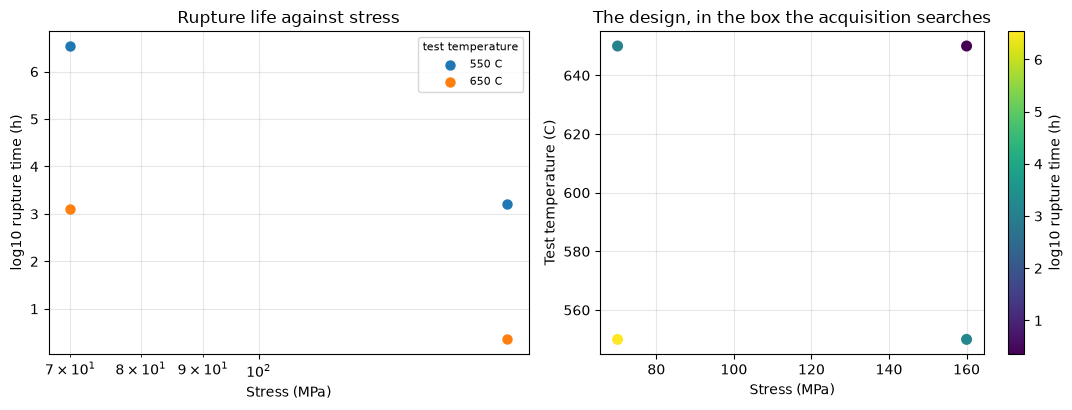

In [11]:
plot_dataset(campaign)
plt.tight_layout()
plt.show()

---
<a id="section-2"></a>
## 2. Active learning on the Engine

Everything that models — the GP, the acquisition, the scoring — runs on the
**remote Uncertainty Engine**, not in this process. The cell below assembles
six workflow graphs and saves them to the project, after which they are
visible in the Engine GUI and can be inspected, re-run and edited there. That
is the point of building them programmatically rather than only executing them.

| Workflow | Nodes | Purpose |
| --- | --- | --- |
| **Train model** | `LoadDataset` → `FilterDataset` ×2 → `ModelConfig` → `TrainModel` → `Save` | Fit a GP to the programme so far |
| **Active Learning** | `LoadModel` → `Recommend` → `Save` | Which (stress, temperature) to test next |
| **GP plot** | `LoadModel` + `CreateDatasetSlice` → `PredictModel` → `UncertaintyPlot` | The design-temperature slice, returned inline with the job |
| **Predict slice** | `LoadModel` + `CreateDatasetSlice` → `PredictModel` → `Save` ×2 | The same slice, **saved** as project datasets |
| **Predict surface** | `LoadModel` + `LoadDataset` → `FilterDataset` → `PredictModel` → `Save` ×2 | The whole two-dimensional posterior |
| **Validate** | `LoadModel` + `LoadDataset` → `FilterDataset` ×2 → `PredictModel` → `ScoreModel` + `ParityPlot` | Scores and a parity plot |

Two things differ from the one-dimensional case. `CreateDatasetSlice` sweeps a
single variable and holds the rest at `fixed_values`, so the **GP plot** and
**Predict slice** workflows read the surface one temperature at a time — here,
at `DESIGN_TEMPERATURE`. To see the surface itself, the grid is built locally,
uploaded as an ordinary dataset and predicted over, which is what **Predict
surface** does.

And `Recommend` takes no bounds. It searches the domain the trained model has
seen, so the four corners in `SEED_DESIGN` are what define the box the
acquisition may roam in — not `STRESS_BOUNDS` and `TEMPERATURE_BOUNDS`, which
only bound the simulator and the plots.

The programme is uploaded as **one** dataset and `FilterDataset` splits out the
input and output columns, so each iteration re-uploads a single CSV.

In [12]:
#@title Engine workflow builders { display-mode: "form" }
# Covers, in three groups.
#
# Datasets
#   resource_id()        a project resource's id by name, or None.
#   upload_dataset()     write a frame to the project; *create* on the first
#                        call, *new version of the same id* after that. The
#                        saved workflows point at that id, so it must not move.
#   download_dataset()   a dataset resource back as a frame.
#
# Graph builders — five of the six workflows, matching the ones exported from the GUI
#   build_training_workflow()        LoadDataset -> FilterDataset x2 ->
#                                    ModelConfig -> TrainModel -> Save
#   build_recommendation_workflow()  LoadModel -> Recommend -> Save
#   build_gp_plot_workflow()         LoadModel + CreateDatasetSlice ->
#                                    PredictModel -> UncertaintyPlot
#   build_prediction_workflow()      the same posterior, but *saved* as two
#                                    project datasets rather than a plot payload
#   build_validation_workflow()      ... -> ScoreModel + ParityPlot
#
# Running and reading
#   save_workflow()      put a graph in the project workspace, by name. It then
#                        shows up in the GUI and can be re-run and edited there.
#   run_saved()          run one by id, optionally overriding node inputs.
#   outputs()            unwrap `JobInfo.outputs`, which nests the map one deep.
#   uncertainty_curve()  the posterior a GP-plot job returns inline.
#   saved_prediction()   the posterior a prediction job saved, downloaded.
#   recommended_points() the points a recommendation job chose.
#
# Node schemas are resolved from the Node Registry at run time (SDK >= 0.15),
# so these follow whatever version the Engine currently serves.

#: Our acquisition names mapped onto the SDK's `AvailableAcquisitions`.
ACQUISITIONS: Dict[str, str] = {
    # Uncertainty reduction - what a characterisation campaign wants.
    "qNIPV": "MonteCarloNegativeIntegratedPosteriorVariance",
    "PSD": "PosteriorStandardDeviation",
    # Optimisation - these chase the *longest* life, not the design stress,
    # so they are the wrong tool here and are listed for completeness.
    "EI": "ExpectedImprovement",
    "LogEI": "LogExpectedImprovement",
    "qEI": "MonteCarloExpectedImprovement",
    "qLogEI": "MonteCarloLogExpectedImprovement",
    "PM": "PosteriorMean",
}

#: The campaign columns the GP is trained on.
INPUT_COLUMNS: List[str] = [STRESS_COL, TEMPERATURE_COL]
OUTPUT_COLUMNS: List[str] = [LOG_LIFE_COL]


# ----- datasets -------------------------------------------------------------
def resource_id(client, project_id: str, name: str, resource_type: str = "dataset"):
    """The id of a project resource by name, or ``None`` if there is no such one."""
    records = client.resources.list_resources(project_id, resource_type)
    matches = [r for r in records if getattr(r, "name", None) == name]
    if not matches:
        return None
    if len(matches) > 1:
        raise RuntimeError(
            f"{len(matches)} {resource_type} resources are named {name!r} in this "
            "project; rename or delete the duplicates."
        )
    return matches[0].id


def upload_dataset(client, project_id: str, frame: pd.DataFrame, name: str) -> str:
    """Write a frame to the project workspace and return its resource id.

    Creating and versioning are *different calls*: ``upload`` refuses a name the
    project already holds (409 Conflict), and ``update`` adds a new version to
    an existing resource, keeping its id. The active-learning loop depends on
    that id staying put — the saved workflows point at it — so this picks the
    right call rather than assuming either.
    """
    existing = resource_id(client, project_id, name)
    with tempfile.TemporaryDirectory() as directory:
        path = Path(directory) / f"{name}.csv"
        frame.to_csv(path, index=False)
        if existing is None:
            client.resources.upload(
                project_id=project_id, name=name,
                resource_type="dataset", file_path=str(path),
            )
        else:
            client.resources.update(
                project_id=project_id, resource_type="dataset",
                resource_id=existing, file_path=str(path),
            )

    return existing or client.resources.get_resource_id_by_name(
        resource_type="dataset", project_id=project_id, name=name
    )


def download_dataset(client, project_id: str, resource_id_: str) -> pd.DataFrame:
    """Download a dataset resource and parse it as a frame."""
    content = client.resources.download(
        project_id=project_id, resource_type="dataset", resource_id=resource_id_
    )
    return pd.read_csv(io.BytesIO(content))


# ----- node and graph plumbing ----------------------------------------------
def _node(client, node_name: str, label: str, **inputs):
    """Build a node by name; the schema is resolved from the Node Registry."""
    return client.nodes(node_name, label=label, **inputs)


def _resource(resource_id_: str) -> Dict[str, str]:
    """A resource id in the serialised form the load nodes take."""
    from uncertainty_engine_types import ResourceID

    return ResourceID(id=resource_id_).model_dump()


def _workflow(graph, requested_output: Dict[str, Any], client):
    """Wrap a populated graph as an executable workflow."""
    from uncertainty_engine.nodes.workflow import Workflow

    return Workflow(
        graph=graph.nodes,
        inputs=graph.external_input,
        requested_output=requested_output,
        external_input_id=graph.external_input_id,
        client=client,
    )


def _graph():
    """A graph that refuses duplicate labels, since every label here is fixed."""
    from uncertainty_engine.graph import Graph

    return Graph(prevent_node_overwrite=True)


def _output(label: str, handle: str) -> Dict[str, Dict[str, str]]:
    """One entry of a workflow's ``requested_output`` map."""
    return {f"{label}_{handle}": {"node_name": label, "node_handle": handle}}


def _load_dataset(client, project_id: str, resource_id_: str, label: str):
    """A ``LoadDataset`` node. Its output handle is ``file``, not ``dataset``."""
    return _node(client, "LoadDataset", label,
                 project_id=project_id, file_id=_resource(resource_id_))


def _load_model(client, project_id: str, resource_id_: str, label: str):
    """A ``LoadModel`` node. Its output handle is ``file``, not ``model``."""
    return _node(client, "LoadModel", label,
                 project_id=project_id, file_id=_resource(resource_id_))


def _filter(client, source, label: str, columns: Sequence[str]):
    """A ``FilterDataset`` node selecting ``columns`` from a loaded dataset."""
    return _node(client, "FilterDataset", label,
                 dataset=source.make_handle("file"),
                 columns=list(columns), sample_fraction=1)


def _save(client, source, handle: str, project_id: str, file_name: str, label: str):
    """A ``Save`` node. The node input is ``file_id``; it holds the *name*."""
    return _node(client, "Save", label,
                 data=source.make_handle(handle), file_id=file_name,
                 project_id=project_id, account_id=None)


def _slice(client, bounds, num_points: int, variable: Optional[str] = None,
           fixed: Optional[Dict[str, float]] = None):
    """A ``CreateDatasetSlice`` node: sweep one input, hold the others.

    ``fixed`` is what makes a multi-input model sliceable at all. The node
    sweeps ``variable`` and holds every name in ``fixed`` at its value, so a
    two-input model is read one line at a time.
    """
    return _node(client, "CreateDatasetSlice", "Slice",
                 variable=variable or INPUT_COLUMNS[0],
                 min=str(bounds[0]), max=str(bounds[1]),
                 fixed_values=dict(fixed or {}), num_points=num_points)


# ----- the workflows --------------------------------------------------------
def build_training_workflow(
    client, project_id: str, dataset_resource_id: str, model_name: str,
    kernel: str = "LIN+RBF", model_type: str = "SingleTaskGPTorch",
    warp_inputs: bool = False, seed: Optional[int] = 0,
    input_columns: Optional[Sequence[str]] = None,
    output_columns: Optional[Sequence[str]] = None,
):
    """Train a GP on the campaign so far and save the fitted model.

    The campaign is uploaded as *one* dataset; ``FilterDataset`` splits out the
    input and output columns, so the loop re-uploads a single CSV per iteration.
    """
    graph = _graph()

    data = _load_dataset(client, project_id, dataset_resource_id, "Experimental Data")
    inputs_ = _filter(client, data, "Inputs", input_columns or INPUT_COLUMNS)
    life = _filter(client, data, "Life", output_columns or OUTPUT_COLUMNS)
    config = _node(client, "ModelConfig", "Gaussian Process",
                   model_type=model_type, kernel=kernel,
                   warp_inputs=warp_inputs, seed=seed)
    for node in (data, inputs_, life, config):
        graph.add_node(node)

    train = _node(client, "TrainModel", "Train Model",
                  config=config.make_handle("config"),
                  inputs=inputs_.make_handle("dataset"),
                  outputs=life.make_handle("dataset"))
    save = _save(client, train, "model", project_id, model_name, "Save")
    graph.add_node(train)
    graph.add_node(save)

    return _workflow(graph, _output("Save", "saved_resource"), client)


def build_recommendation_workflow(
    client, project_id: str, model_resource_id: str, points_name: str,
    acquisition: str = "qNIPV", num_points: int = 1,
):
    """Ask the trained GP for the next test condition(s)."""
    if acquisition not in ACQUISITIONS:
        raise ValueError(f"acquisition must be one of {sorted(ACQUISITIONS)}, got {acquisition!r}")
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    graph.add_node(model)

    recommend = _node(client, "Recommend", "Active Learning",
                      model=model.make_handle("file"),
                      number_of_points=str(num_points),
                      acquisition_function=ACQUISITIONS[acquisition])
    save = _save(client, recommend, "recommended_points", project_id, points_name, "Save")
    graph.add_node(recommend)
    graph.add_node(save)

    # `recommended_points` comes back as an S3 reference, not as values, so the
    # saved resource is what the loop actually reads.
    requested = {**_output("Save", "saved_resource"),
                 **_output("Active Learning", "recommended_points")}
    return _workflow(graph, requested, client)


def build_gp_plot_workflow(
    client, project_id: str, model_resource_id: str, bounds,
    num_points: int = 101, variable: Optional[str] = None,
    fixed: Optional[Dict[str, float]] = None,
):
    """Predict across a one-variable slice — the model visualisation."""
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    slice_ = _slice(client, bounds, num_points, variable, fixed)
    graph.add_node(model)
    graph.add_node(slice_)

    predict = _node(client, "PredictModel", "Predict",
                    model=model.make_handle("file"),
                    dataset=slice_.make_handle("data"))
    plot = _node(client, "UncertaintyPlot", "Uncertainty Plot",
                 X=slice_.make_handle("data"),
                 prediction=predict.make_handle("prediction"),
                 uncertainty=predict.make_handle("uncertainty"))
    graph.add_node(predict)
    graph.add_node(plot)

    # `UncertaintyPlot` returns the whole curve inline — x_vals, mean, std —
    # which is the only posterior that comes back as values. `PredictModel`'s
    # own handles return S3 references, so they are not requested here.
    requested = {**_output("Uncertainty Plot", "data"), **_output("Slice", "data")}
    return _workflow(graph, requested, client)


def build_prediction_workflow(
    client, project_id: str, model_resource_id: str, bounds,
    mean_name: str, uncertainty_name: str,
    num_points: int = 101, variable: Optional[str] = None,
    fixed: Optional[Dict[str, float]] = None,
):
    """Predict across a slice and **save** the posterior as project datasets.

    The same shape as `build_gp_plot_workflow`, but where that one returns a
    plot payload that lives only as long as the job, this writes the posterior
    mean and uncertainty to the project, where they persist and can be opened
    in the GUI. They are separate resources because `PredictModel` emits them
    as separate handles and no node here joins two datasets.
    """
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    slice_ = _slice(client, bounds, num_points, variable, fixed)
    graph.add_node(model)
    graph.add_node(slice_)

    predict = _node(client, "PredictModel", "Predict",
                    model=model.make_handle("file"),
                    dataset=slice_.make_handle("data"))
    save_mean = _save(client, predict, "prediction", project_id, mean_name, "Save Mean")
    save_sd = _save(client, predict, "uncertainty", project_id, uncertainty_name, "Save Uncertainty")
    for node in (predict, save_mean, save_sd):
        graph.add_node(node)

    requested = {**_output("Save Mean", "saved_resource"),
                 **_output("Save Uncertainty", "saved_resource"),
                 **_output("Slice", "data")}
    return _workflow(graph, requested, client)


def build_validation_workflow(
    client, project_id: str, model_resource_id: str, dataset_resource_id: str,
    metrics: Sequence[str] = ("MSE", "RMSE", "R2"),
    input_columns: Optional[Sequence[str]] = None,
    output_columns: Optional[Sequence[str]] = None,
):
    """Score the model against a held-out dataset and draw a parity plot."""
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    data = _load_dataset(client, project_id, dataset_resource_id, "Validation Data")
    inputs_ = _filter(client, data, "Inputs", input_columns or INPUT_COLUMNS)
    life = _filter(client, data, "Life", output_columns or OUTPUT_COLUMNS)
    for node in (model, data, inputs_, life):
        graph.add_node(node)

    predict = _node(client, "PredictModel", "Predict",
                    model=model.make_handle("file"),
                    dataset=inputs_.make_handle("dataset"))
    score = _node(client, "ScoreModel", "Score",
                  predictions=predict.make_handle("prediction"),
                  truth=life.make_handle("dataset"),
                  predictions_uncertainty=predict.make_handle("uncertainty"),
                  metrics=list(metrics))
    parity = _node(client, "ParityPlot", "Parity Plot",
                   predictions=predict.make_handle("prediction"),
                   expected=life.make_handle("dataset"),
                   uncertainties=predict.make_handle("uncertainty"))
    for node in (predict, score, parity):
        graph.add_node(node)

    requested = {**_output("Score", "scores"), **_output("Parity Plot", "plot")}
    return _workflow(graph, requested, client)


# ----- the workspace --------------------------------------------------------
def workflow_id(client, project_id: str, name: str):
    """The id of a saved workflow by name, or ``None`` if there is no such one."""
    records = client.workflows.list_workflows(project_id)
    matches = [r for r in records if getattr(r, "name", None) == name]
    return matches[0].id if matches else None


def save_workflow(client, project_id: str, workflow, name: str) -> str:
    """Save a workflow to the project workspace and return its id.

    Workflow names are unique within a project, so saving over an existing name
    updates that workflow as a new version instead of failing. Re-running this
    notebook therefore revises its workflows rather than duplicating them.
    """
    existing = workflow_id(client, project_id, name)
    if existing is not None:
        return client.workflows.save(project_id=project_id, workflow=workflow, workflow_id=existing)
    return client.workflows.save(project_id=project_id, workflow=workflow, workflow_name=name)


def _completed(response):
    """Return a finished job, or raise with the response body if it failed."""
    if response.status.value != "completed":
        raise RuntimeError(
            f"Workflow did not complete (status {response.status.value}): {response.model_dump()}"
        )
    return response


def run_saved(client, project_id: str, workflow_id_: str, overrides=None):
    """Run a workflow already saved in the project, by id.

    The loop's workhorse: the graphs are built and saved once, then re-run each
    iteration. Nothing needs overriding for that, because every iteration
    re-uploads its dataset under the same resource *name* — a new version of
    the same resource id, which the saved graph already points at.

    ``overrides`` maps ``(node_label, input_handle)`` to a value, for the cases
    where you do want to vary something, such as the acquisition function.
    """
    from uncertainty_engine_types import OverrideWorkflowInput

    inputs = [
        OverrideWorkflowInput(node_label=label, input_handle=handle, value=value)
        for (label, handle), value in (overrides or {}).items()
    ]
    return _completed(
        client.run_workflow(project_id=project_id, workflow_id=workflow_id_, inputs=inputs or None)
    )


# ----- reading results back -------------------------------------------------
def outputs(response) -> Dict[str, Any]:
    """The requested outputs of a finished job, keyed as the builders named them.

    ``JobInfo.outputs`` wraps the map in another ``"outputs"`` key; this unwraps
    it, so callers see the ``"<label>_<handle>"`` keys that were asked for.
    """
    payload = dict(response.outputs or {})
    inner = payload.get("outputs")
    return dict(inner) if isinstance(inner, dict) else payload


def as_frame(payload: Any) -> pd.DataFrame:
    """A node output that carries a CSV payload, as a frame.

    Several nodes (``ScoreModel``, ``CreateDatasetSlice``) return their result
    as ``{"csv": "..."}`` rather than as records.
    """
    if isinstance(payload, dict) and "csv" in payload:
        return pd.read_csv(io.StringIO(payload["csv"]))
    return pd.DataFrame(payload)


def uncertainty_curve(response) -> pd.DataFrame:
    """The posterior from a GP-plot job: grid, mean and standard deviation."""
    data = outputs(response)["Uncertainty Plot_data"]
    label = data.get("x_label", INPUT_COLUMNS[0])
    return pd.DataFrame(
        {label: data["x_vals"], "mean": data["mean"], "sd": data["std"]}
    ).sort_values(label, ignore_index=True)


def saved_prediction(client, project_id: str, response) -> pd.DataFrame:
    """The posterior a prediction job saved, as one frame.

    Downloads the two saved datasets and puts them beside the grid, which came
    back inline with the job. Columns: the input variable, ``mean`` and ``sd``.
    """
    out = outputs(response)
    grid = as_frame(out["Slice_data"])
    mean = download_dataset(client, project_id, out["Save Mean_saved_resource"]["id"])
    sd = download_dataset(client, project_id, out["Save Uncertainty_saved_resource"]["id"])

    frame = pd.DataFrame(
        {
            grid.columns[0]: grid.iloc[:, 0].to_numpy(dtype=float),
            "mean": mean.iloc[:, 0].to_numpy(dtype=float),
            "sd": sd.iloc[:, 0].to_numpy(dtype=float),
        }
    )
    return frame.sort_values(frame.columns[0], ignore_index=True)


def recommended_points(client, project_id: str, response) -> pd.DataFrame:
    """The points a recommendation job chose, downloaded from its saved resource.

    The ``recommended_points`` handle is an S3 reference; the ``Save`` node's
    ``saved_resource`` carries the resource id, which is what can be read back.
    """
    saved = outputs(response)["Save_saved_resource"]
    return download_dataset(client, project_id, saved["id"])


def build_grid_prediction_workflow(
    client, project_id: str, model_resource_id: str, grid_resource_id: str,
    mean_name: str, uncertainty_name: str,
    input_columns: Optional[Sequence[str]] = None,
):
    """Predict over a whole uploaded grid, rather than a one-variable slice.

    `CreateDatasetSlice` sweeps a single input, which is all a one-input model
    ever needs. A two-input model has a *surface*, so the grid is built here,
    uploaded as an ordinary dataset and loaded like any other. `PredictModel`
    returns its rows in the order it was given them, so the posterior can be
    put straight back beside the grid frame.
    """
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    data = _load_dataset(client, project_id, grid_resource_id, "Grid")
    inputs = _filter(client, data, "Inputs", input_columns or INPUT_COLUMNS)
    for node in (model, data, inputs):
        graph.add_node(node)

    predict = _node(client, "PredictModel", "Predict",
                    model=model.make_handle("file"),
                    dataset=inputs.make_handle("dataset"))
    save_mean = _save(client, predict, "prediction", project_id, mean_name, "Save Mean")
    save_sd = _save(client, predict, "uncertainty", project_id, uncertainty_name, "Save Uncertainty")
    for node in (predict, save_mean, save_sd):
        graph.add_node(node)

    requested = {**_output("Save Mean", "saved_resource"),
                 **_output("Save Uncertainty", "saved_resource")}
    return _workflow(graph, requested, client)


def saved_surface(client, project_id: str, response, grid: pd.DataFrame) -> pd.DataFrame:
    """The posterior a grid-prediction job saved, beside the grid it was asked for."""
    out = outputs(response)
    mean = download_dataset(client, project_id, out["Save Mean_saved_resource"]["id"])
    sd = download_dataset(client, project_id, out["Save Uncertainty_saved_resource"]["id"])

    frame = grid.copy()
    frame["mean"] = mean.iloc[:, 0].to_numpy(dtype=float)
    frame["sd"] = sd.iloc[:, 0].to_numpy(dtype=float)
    return frame

The programme and the prediction grid have to exist before the graphs can point at them, so both are uploaded first. Re-running this cell adds a new **version** of each resource rather than a new resource, which is what lets the saved workflows keep working.

In [13]:
DATASET_NAME = "creep_programme"
GRID_NAME = "creep_grid"
MODEL_NAME = "creep_gp"
POINTS_NAME = "creep_next_point"
MEAN_NAME = "creep_gp_mean"
UNCERTAINTY_NAME = "creep_gp_sd"
SURFACE_MEAN_NAME = "creep_surface_mean"
SURFACE_SD_NAME = "creep_surface_sd"

# The grid the surface is read on. Uploaded once; the saved workflow points at
# its resource id, so it never needs rebuilding.
grid_stress = np.linspace(*STRESS_BOUNDS, 48)
grid_temperature = np.linspace(*TEMPERATURE_BOUNDS, 48)
mesh_stress, mesh_temperature = np.meshgrid(grid_stress, grid_temperature)
grid_frame = pd.DataFrame({
    STRESS_COL: mesh_stress.ravel(),
    TEMPERATURE_COL: mesh_temperature.ravel(),
})

dataset_id = upload_dataset(client, project_id, campaign, DATASET_NAME)
grid_id = upload_dataset(client, project_id, grid_frame, GRID_NAME)
print(f"programme resource: {dataset_id}")
print(f"grid resource:      {grid_id}  ({len(grid_frame)} points)")

programme resource: 6aea01aebac4a9e13468fd0a
grid resource:      6aea01aebac4a9e13468fd0d  (2304 points)


In [14]:
training = build_training_workflow(
    client, project_id, dataset_id, MODEL_NAME,
    kernel=KERNEL, model_type=MODEL_TYPE, warp_inputs=WARP_INPUTS, seed=MODEL_SEED,
)
training_id = save_workflow(client, project_id, training, "Creep - Train model")

run_saved(client, project_id, training_id)
model_id = resource_id(client, project_id, MODEL_NAME, "model")
print(f"model resource: {model_id}")

model resource: 6aea01c2bac4a9e13468fd12


In [15]:
# Every slice is taken at the design temperature, which is the only line
# through the surface this notebook's question is asked on.
DESIGN_SLICE = {TEMPERATURE_COL: DESIGN_TEMPERATURE}

workflows = {
    "Creep - Active learning": build_recommendation_workflow(
        client, project_id, model_id, POINTS_NAME,
        acquisition=ACQUISITION, num_points=POINTS_PER_ITERATION,
    ),
    "Creep - GP plot": build_gp_plot_workflow(
        client, project_id, model_id, STRESS_BOUNDS, fixed=DESIGN_SLICE
    ),
    "Creep - Predict design slice": build_prediction_workflow(
        client, project_id, model_id, STRESS_BOUNDS, MEAN_NAME, UNCERTAINTY_NAME,
        fixed=DESIGN_SLICE,
    ),
    "Creep - Predict surface": build_grid_prediction_workflow(
        client, project_id, model_id, grid_id, SURFACE_MEAN_NAME, SURFACE_SD_NAME
    ),
    "Creep - Validate": build_validation_workflow(
        client, project_id, model_id, dataset_id
    ),
}

saved_ids = {
    name: save_workflow(client, project_id, workflow, name)
    for name, workflow in workflows.items()
}
saved_ids["Creep - Train model"] = training_id

for name, wid in saved_ids.items():
    print(f"{name:40s} {wid}")

Creep - Active learning                  6aea01c6bac4a9e13468fd15
Creep - GP plot                          6aea01c7bac4a9e13468fd17
Creep - Predict design slice             6aea01c7bac4a9e13468fd19
Creep - Predict surface                  6aea01c7bac4a9e13468fd1b
Creep - Validate                         6aea01c7bac4a9e13468fd1d
Creep - Train model                      6aea01b0bac4a9e13468fd10


### The loop

Train, look, choose, test, re-upload. Nothing is rebuilt inside the loop: the
six graphs are already saved, and each iteration re-uploads the programme under
the same resource *name*, which versions the resource the graphs point at.

In [16]:
history = []

for iteration in range(1, ITERATIONS + 1):
    # 1. Train on everything ruptured so far.
    run_saved(client, project_id, saved_ids["Creep - Train model"])

    # 2. The design-temperature slice, for the plots below.
    curve = uncertainty_curve(
        run_saved(client, project_id, saved_ids["Creep - GP plot"])
    )

    # 3. Ask the acquisition where to test next. In two dimensions the answer
    #    is a (stress, temperature) pair, not a single number.
    points = recommended_points(
        client, project_id,
        run_saved(client, project_id, saved_ids["Creep - Active learning"]),
    )
    picked = [(float(s), float(t))
              for s, t in zip(points[STRESS_COL], points[TEMPERATURE_COL])]

    history.append({
        "iteration": iteration,
        "n_tests": len(campaign),
        "curve": curve,
        "observed": campaign[[STRESS_COL, TEMPERATURE_COL, LOG_LIFE_COL]].copy(),
        "picked": picked,
    })
    print(f"iteration {iteration}: {len(campaign)} tests -> next at "
          + ", ".join(f"{s:.1f} MPa / {t:.1f} C" for s, t in picked))

    # 4. Run those tests on the simulator and grow the programme.
    new_rows = simulator.run(picked, start_index=len(campaign) + 1)
    campaign = pd.concat([campaign, new_rows], ignore_index=True)

    # 5. Re-upload: a new version of the same resource id.
    upload_dataset(client, project_id, campaign, DATASET_NAME)

print(f"\nfinished with {len(campaign)} tests")

iteration 1: 4 tests -> next at 117.9 MPa / 601.8 C


iteration 2: 5 tests -> next at 114.6 MPa / 598.3 C


iteration 3: 6 tests -> next at 70.4 MPa / 605.4 C


iteration 4: 7 tests -> next at 110.4 MPa / 632.2 C


iteration 5: 8 tests -> next at 157.1 MPa / 606.1 C


iteration 6: 9 tests -> next at 118.2 MPa / 565.7 C


iteration 7: 10 tests -> next at 70.1 MPa / 580.0 C


iteration 8: 11 tests -> next at 158.1 MPa / 576.4 C



finished with 12 tests


### What the model learned

Each panel is the **design-temperature slice** through the fitted surface after
that iteration, with the target life drawn across it. Most of the specimens are
not on this line — the acquisition is free to test anywhere in the box, and
mostly does — so what the panels show is how knowledge gathered *elsewhere*
in the (stress, temperature) plane propagates onto the line the question is
asked on. That propagation is the Larson–Miller trade, learned rather than
assumed.

the truth to beat: 100.00 MPa carries 100,000 h at 550 C


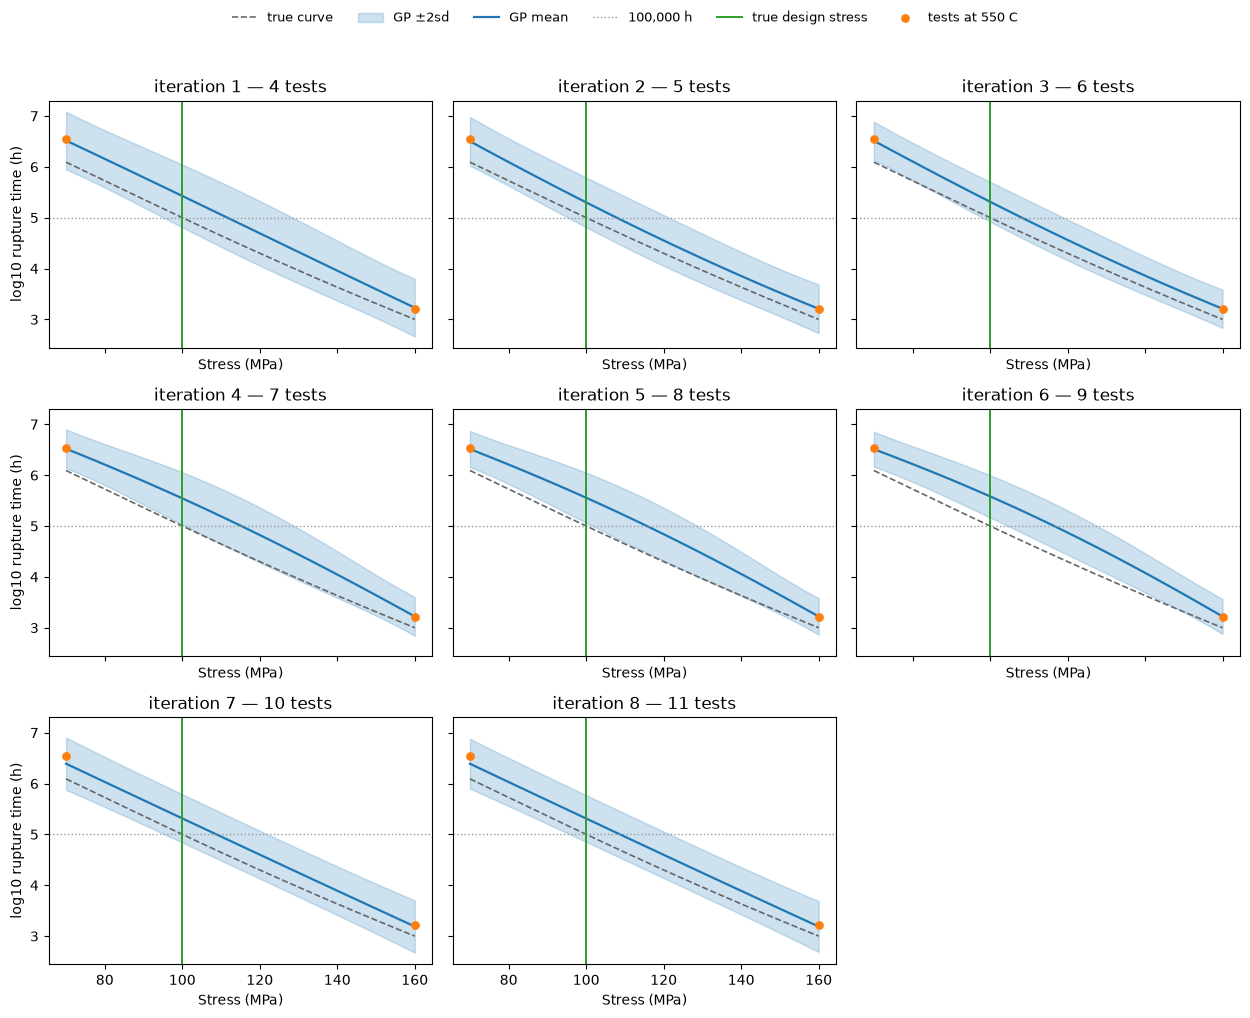

In [17]:
target_level = float(np.log10(TARGET_LIFE_HOURS))
true_design_stress = simulator.stress_for_life(DESIGN_TEMPERATURE, target_level)
stress_grid = np.linspace(*STRESS_BOUNDS, 400)
truth_slice = simulator.true_log_life(stress_grid, DESIGN_TEMPERATURE)
on_slice = np.isclose(campaign[TEMPERATURE_COL], DESIGN_TEMPERATURE)

print(f"the truth to beat: {true_design_stress:.2f} MPa carries "
      f"{TARGET_LIFE_HOURS:,.0f} h at {DESIGN_TEMPERATURE:g} C")

columns = 3
rows = int(np.ceil(len(history) / columns))
fig, axes = plt.subplots(
    rows, columns, figsize=(4.2 * columns, 3.4 * rows), sharex=True, sharey=True
)
axes = np.atleast_1d(axes).ravel()

for ax, step in zip(axes, history):
    panel = step["curve"]
    s = panel[STRESS_COL].to_numpy()
    mean, sd = panel["mean"].to_numpy(), panel["sd"].to_numpy()

    ax.plot(stress_grid, truth_slice, color=COLOURS["truth"], lw=1.2, ls="--",
            label="true curve")
    ax.fill_between(s, mean - 2 * sd, mean + 2 * sd, alpha=0.22,
                    color=COLOURS["gp"], label="GP ±2sd")
    ax.plot(s, mean, color=COLOURS["gp"], lw=1.6, label="GP mean")
    ax.axhline(target_level, color="0.6", lw=1.0, ls=":",
               label=f"{TARGET_LIFE_HOURS:,.0f} h")
    ax.axvline(true_design_stress, color=COLOURS["true_design"], lw=1.4,
               label="true design stress")

    seen = step["observed"]
    here = np.isclose(seen[TEMPERATURE_COL], DESIGN_TEMPERATURE)
    if here.any():
        ax.scatter(seen.loc[here, STRESS_COL], seen.loc[here, LOG_LIFE_COL],
                   s=28, color=COLOURS["tests"], zorder=3,
                   label=f"tests at {DESIGN_TEMPERATURE:g} C")

    # The count goes in the title: a shared legend can only carry one label,
    # so putting it there would show every panel the last panel's count.
    ax.set_title(f"iteration {step['iteration']} — {step['n_tests']} tests")

for ax in axes[len(history):]:
    ax.set_visible(False)
for ax in axes[:len(history)]:
    ax.set_xlabel(STRESS_COL)
for ax in axes[::columns]:
    ax.set_ylabel(LOG_LIFE_COL)

handles, labels = axes[0].get_legend_handles_labels()
seen_labels = dict(zip(labels, handles))
fig.legend(seen_labels.values(), seen_labels.keys(), loc="upper center",
           ncol=6, frameon=False, fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### Where the acquisition chose to test

This is the figure the one-dimensional notebook cannot draw. The dashed line
is the locus of conditions whose true life is exactly the design life — the
answer, as a curve through the box — and it drops out of the bottom of the
tested stress range at about 586 °C, which is why the design temperature has
to sit where it does.

Watch whether the acquisition walks towards that line. It has no idea the line
exists: `qNIPV` reduces integrated posterior variance over the whole box and
knows nothing of the question being asked at the end.

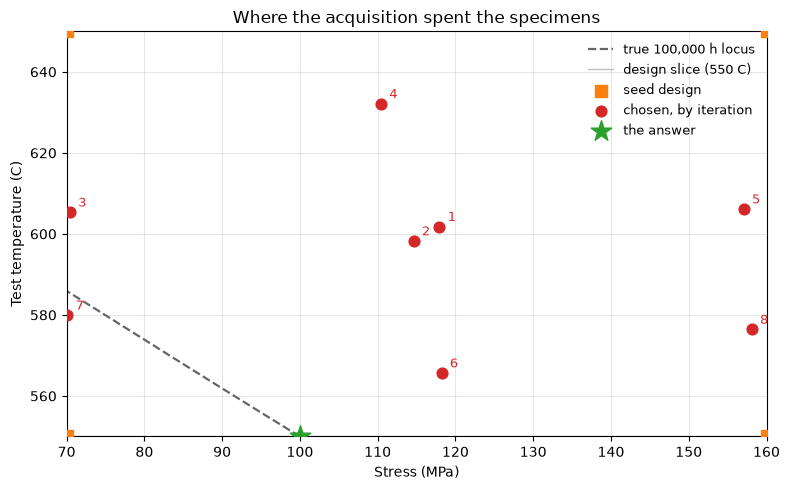

In [18]:
locus_temperature, locus_stress = [], []
for temperature in np.linspace(*TEMPERATURE_BOUNDS, 200):
    try:
        locus_stress.append(simulator.stress_for_life(temperature, target_level))
        locus_temperature.append(temperature)
    except ValueError:
        break                      # the design life leaves the stress box here

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(locus_stress, locus_temperature, color=COLOURS["truth"], lw=1.6, ls="--",
        label=f"true {TARGET_LIFE_HOURS:,.0f} h locus")
ax.axhline(DESIGN_TEMPERATURE, color="0.75", lw=1.0,
           label=f"design slice ({DESIGN_TEMPERATURE:g} C)")

seed = campaign.iloc[:len(SEED_DESIGN)]
ax.scatter(seed[STRESS_COL], seed[TEMPERATURE_COL], s=70, marker="s",
           color=COLOURS["tests"], zorder=3, label="seed design")
for step in history:
    for stress, temperature in step["picked"]:
        ax.scatter([stress], [temperature], s=60, color=COLOURS["picked"], zorder=4)
        ax.annotate(str(step["iteration"]), (stress, temperature),
                    textcoords="offset points", xytext=(6, 4),
                    fontsize=9, color=COLOURS["picked"])
ax.scatter([], [], s=60, color=COLOURS["picked"], label="chosen, by iteration")
ax.scatter([true_design_stress], [DESIGN_TEMPERATURE], marker="*", s=240,
           color=COLOURS["true_design"], zorder=5, label="the answer")

ax.set_xlim(*STRESS_BOUNDS)
ax.set_ylim(*TEMPERATURE_BOUNDS)
ax.set_xlabel(STRESS_COL)
ax.set_ylabel(TEMPERATURE_COL)
ax.set_title("Where the acquisition spent the specimens")
ax.legend(frameon=False, fontsize=9, loc="upper right")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### The posterior, saved to the project

The **Predict design slice** and **Predict surface** workflows write the fitted
posterior back into the project as datasets, where it outlives the job and can
be opened in the GUI. The slice is the line the question is asked on; the
surface is everything the campaign learned.

In [19]:
run_saved(client, project_id, saved_ids["Creep - Train model"])  # train on the final programme

posterior_curve = saved_prediction(
    client, project_id,
    run_saved(client, project_id, saved_ids["Creep - Predict design slice"]),
)
surface = saved_surface(
    client, project_id,
    run_saved(client, project_id, saved_ids["Creep - Predict surface"]),
    grid_frame,
)
print(f"slice saved as {MEAN_NAME!r} / {UNCERTAINTY_NAME!r}")
print(f"surface saved as {SURFACE_MEAN_NAME!r} / {SURFACE_SD_NAME!r}"
      f"  ({len(surface)} points)")
posterior_curve.head()

slice saved as 'creep_gp_mean' / 'creep_gp_sd'
surface saved as 'creep_surface_mean' / 'creep_surface_sd'  (2304 points)


,Stress (MPa),mean,sd
0,70.0,6.391307,0.231118
1,70.9,6.358823,0.230242
2,71.8,6.326347,0.229409
3,72.7,6.293877,0.228618
4,73.6,6.261415,0.227868


### The surface the campaign bought

Left, the posterior mean: filled contours of $\log_{10} t_r$ over the box, with
the fitted design-life contour against the true one. Right, the posterior
standard deviation — where the model is still unsure. The specimens are drawn
on both.

The right-hand panel is the one the acquisition was minimising, and it explains
the left: the fitted contour sits closest to the truth where the uncertainty is
lowest, and drifts where it is not.

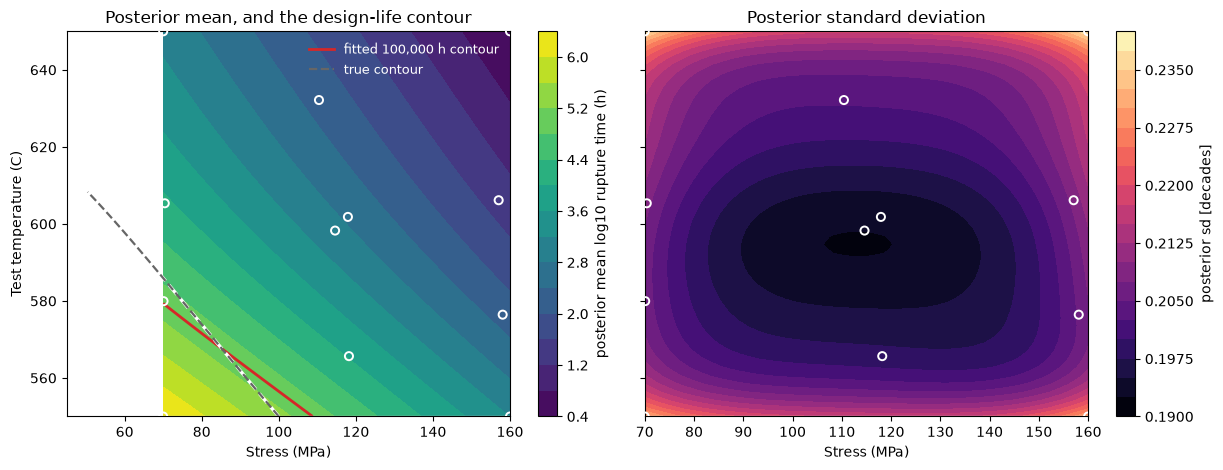

In [20]:
shape = (grid_temperature.size, grid_stress.size)
mesh_mean = surface["mean"].to_numpy().reshape(shape)
mesh_sd = surface["sd"].to_numpy().reshape(shape)

fig, (left, right) = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)

filled = left.contourf(mesh_stress, mesh_temperature, mesh_mean, levels=18, cmap="viridis")
plt.colorbar(filled, ax=left, label="posterior mean " + LOG_LIFE_COL)
left.contour(mesh_stress, mesh_temperature, mesh_mean,
             levels=[target_level], colors=[COLOURS["design"]], linewidths=2.0)
# A contour set carries no legend handle of its own in current matplotlib, so
# the two contours are labelled with proxy lines drawn off the axes.
left.plot([], [], color=COLOURS["design"], lw=2.0,
          label=f"fitted {TARGET_LIFE_HOURS:,.0f} h contour")
left.plot(locus_stress, locus_temperature, color="w", lw=2.4, ls="--")
left.plot(locus_stress, locus_temperature, color=COLOURS["truth"], lw=1.6, ls="--",
          label="true contour")
left.set_title("Posterior mean, and the design-life contour")

spread = right.contourf(mesh_stress, mesh_temperature, mesh_sd, levels=18, cmap="magma")
plt.colorbar(spread, ax=right, label="posterior sd [decades]")
right.set_title("Posterior standard deviation")

for ax in (left, right):
    ax.scatter(campaign[STRESS_COL], campaign[TEMPERATURE_COL], s=34,
               facecolor="none", edgecolor="w", lw=1.4, zorder=4)
    ax.axhline(DESIGN_TEMPERATURE, color="w", lw=1.0, alpha=0.7)
    ax.set_xlabel(STRESS_COL)
left.set_ylabel(TEMPERATURE_COL)
left.legend(frameon=False, fontsize=9, loc="upper right", labelcolor="w")
fig.tight_layout()
plt.show()

### Validation

Scored on its own training data, so these are a check that the fit took, not a
generalisation estimate.

In [21]:
scores = outputs(run_saved(client, project_id, saved_ids["Creep - Validate"]))
as_frame(scores["Score_scores"])

,metric_name,score
0,MSE,0.018498
1,RMSE,0.136007
2,R2,0.992076


---
<a id="section-3"></a>
## 3. The design stress, with its uncertainty

The GP is a good *interpolator*, but it has no notion of a design stress:
reading one off a posterior mean gives a number with no uncertainty attached.
This section answers the question the programme is actually for, from the model
section 2 produced.

Take the design-temperature slice that section 2 saved and draw the target
life $\log_{10} t_r = \log_{10}(100{,}000)$ across it as a horizontal line.
Where the **posterior mean** meets that line is the design stress. Where the
**credible band** still contains it — from where the band's upper edge passes
through the level to where its lower edge does — is the interval: every stress
at which the material could still last exactly the design life.

This is the DBTT notebook's `dbtt_from_curve` with one change. There the level
was *derived* from the curve, as the mid-point of the two shelves it reached;
here the level is **given** by the design life, so the function takes it as an
argument and nothing is inferred from the extent of the slice.

There is no new Engine work here. `posterior_curve` is the slice the **Predict
design slice** workflow already saved to the project and we downloaded above.

> **What this does and does not assume.** Inverting the band needs no
> linearisation and never divides by the slope of the curve, so a flat,
> poorly resolved stress dependence widens the interval rather than being
> flattered by it, and the result is asymmetric in general. But the band is
> *pointwise*, so the coverage is nominal only approximately; and it is
> *predictive*, carrying the material's heat-to-heat scatter, so the interval
> answers "at what stress could a fresh specimen last exactly 100,000 hours?"
> — wider than "where does the underlying master curve cross it?". The notes
> at the end return to both.

In [22]:
#@title Reading a design stress off a fitted slice { display-mode: "form" }
# Covers
#   crossing_from_curve()  where a fitted posterior crosses a level you supply,
#                          with the interval you get by inverting its credible
#                          band. The DBTT notebook's `dbtt_from_curve`, with
#                          the level given rather than derived from the curve.
#   CurveCrossing          what it returns - the crossing, the interval around
#                          it, the level and the gradient there.
#
# The posterior curve itself comes from the Engine (section 2). Everything
# here is arithmetic on that curve, so the cell needs nothing but numpy.


def _erfinv(mass: float) -> float:
    """Inverse error function at ``mass``, by bisection on ``math.erf``.

    Only ever called with one scalar, so a short bisection is cheaper to read
    than the rational approximation and avoids taking scipy back as a
    dependency for a single number.
    """
    import math

    lo, hi = 0.0, 6.0
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        if math.erf(mid) < mass:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)


def _crossings(x: np.ndarray, y: np.ndarray, level: float):
    """Every (position, slope) where ``y`` crosses ``level``, interpolated."""
    above = y >= level
    out = []
    for i in np.flatnonzero(np.diff(above.astype(int)) != 0):
        x0, x1, y0, y1 = x[i], x[i + 1], y[i], y[i + 1]
        slope = (y1 - y0) / (x1 - x0)
        out.append((x0 + (level - y0) / slope if slope != 0 else x0, slope))
    return out


@dataclass
class CurveCrossing:
    """Where a fitted posterior reaches a given level, and how sure that is."""

    at: float                   # where the posterior mean crosses the level
    low: Optional[float]        # interval start; None if it runs off the slice
    high: Optional[float]       # interval end;   None if it runs off the slice
    has_band: bool              # False when no `sd` was given: no interval at all
    credible_mass: float        # the mass of the band that was inverted
    level: float                # the level being crossed
    gradient: float             # curve slope there; reported, not used
    n_crossings: int            # >1 means the mean is not monotonic

    @property
    def width(self) -> Optional[float]:
        """Interval width, or None if either end is unbounded."""
        if self.low is None or self.high is None:
            return None
        return self.high - self.low

    def __repr__(self) -> str:
        if not self.has_band:
            return f"CurveCrossing(at={self.at:.2f}, no band given)"
        fmt = lambda v: "unbounded" if v is None else f"{v:.2f}"
        return (f"CurveCrossing(at={self.at:.2f}, "
                f"{self.credible_mass:.0%} interval "
                f"[{fmt(self.low)}, {fmt(self.high)}])")


def crossing_from_curve(x, mean, level: float, sd=None,
                        credible_mass: float = 0.95) -> CurveCrossing:
    """Read off where a fitted posterior reaches ``level``, with its uncertainty.

    This works on a model's own posterior curve - the mean and standard
    deviation a GP predicts across a slice - rather than on the measurements.

    The interval is the band inverted. Draw ``level`` as a horizontal line
    across the credible band; the positions at which the band still contains
    that line are the positions at which the curve could still be at the
    level. Equivalently, the ends are where the band's two edges cross the
    level, and they are found the same way the crossing itself is - no
    linearisation, and no dividing by the gradient, so a shallow curve widens
    the interval instead of being flattered by it. The interval is asymmetric
    in general, which is the point.

    Two caveats travel with it. The band is *pointwise*, so inverting it gives
    approximately rather than exactly the nominal coverage. And the band is
    *predictive* - it carries the material's specimen-to-specimen scatter - so
    the interval answers "where could a fresh specimen reach this level?",
    which is wider than "where does the underlying curve reach it?".

    ``low`` or ``high`` come back as None when the band still straddles the
    level at the end of the slice: the data does not bound the answer on that
    side, and a wider slice is the fix.
    """
    x = np.asarray(x, dtype=float).reshape(-1)
    y = np.asarray(mean, dtype=float).reshape(-1)
    if x.size != y.size:
        raise ValueError(f"x and mean differ in length: {x.size} vs {y.size}")
    if x.size < 3:
        raise ValueError("need at least three points to locate a crossing")
    if not 0.0 < credible_mass < 1.0:
        raise ValueError(f"credible_mass must lie in (0, 1), got {credible_mass}")

    s = None
    if sd is not None:
        s = np.asarray(sd, dtype=float).reshape(-1)
        # Validate before reordering: indexing a short `sd` with the full
        # ordering raises IndexError rather than saying what is wrong.
        if s.size != x.size:
            raise ValueError(f"sd differs in length: {s.size} vs {x.size}")

    order = np.argsort(x)
    x, y = x[order], y[order]
    if s is not None:
        s = s[order]

    found = _crossings(x, y, level)
    if not found:
        raise ValueError(
            f"the posterior mean never reaches {level:g} across this slice; the "
            "level is outside what the model predicts here"
        )
    # The steepest crossing is the one the question is about; others are wiggle.
    at, gradient = max(found, key=lambda c: abs(c[1]))

    low = high = None
    if s is not None:
        # The two-sided z for this mass, without pulling scipy in for one number.
        z = float(np.sqrt(2.0) * _erfinv(credible_mass))
        hi_edge, lo_edge = y + z * s, y - z * s

        # Where the band straddles the level at all. The mean crosses inside
        # this set by construction, so the run containing the crossing is the
        # interval; other runs belong to other crossings.
        inside = (lo_edge <= level) & (level <= hi_edge)
        here = int(np.argmin(np.abs(x - at)))
        if not inside[here]:                      # only reachable on a tie at
            here = int(np.flatnonzero(inside)[0]) # the very edge of a cell

        start = stop = here
        while start > 0 and inside[start - 1]:
            start -= 1
        while stop < x.size - 1 and inside[stop + 1]:
            stop += 1

        # Refine each end onto whichever edge actually closes the band there.
        # Which one that is depends on the direction of the curve: on a rising
        # curve the band opens as its upper edge reaches the level and shuts as
        # its lower edge passes it, and on a falling curve the roles swap.
        # Picking by `inside` rather than by assumption handles both, and creep
        # life falls with stress where Charpy energy rises with temperature.
        def close(outside: int, a: int, b: int) -> float:
            edge = hi_edge if hi_edge[outside] < level else lo_edge
            x0, x1, e0, e1 = x[a], x[b], edge[a], edge[b]
            return float(x0 + (level - e0) * (x1 - x0) / (e1 - e0)) if e1 != e0 else float(x0)

        if start > 0:
            low = close(start - 1, start - 1, start)
        if stop < x.size - 1:
            high = close(stop + 1, stop, stop + 1)

    return CurveCrossing(
        at=float(at), low=low, high=high, has_band=s is not None,
        credible_mass=float(credible_mass), level=float(level),
        gradient=float(gradient), n_crossings=len(found),
    )

In [23]:
read = crossing_from_curve(
    posterior_curve[STRESS_COL], posterior_curve["mean"], target_level,
    sd=posterior_curve["sd"],
)
print(read)
print(f"  target level: log10 t_r = {read.level:.2f}  "
      f"({TARGET_LIFE_HOURS:,.0f} h at {DESIGN_TEMPERATURE:g} C)")
print(f"  gradient there: {read.gradient:.4f} decades/MPa")
print(f"  interval width: {read.width:.2f} MPa"
      if read.width is not None else
      "  interval unbounded on one side - widen STRESS_BOUNDS")
print(f"  mean crossings found: {read.n_crossings}")

CurveCrossing(at=108.77, 95% interval [96.78, 120.71])
  target level: log10 t_r = 5.00  (100,000 h at 550 C)
  gradient there: -0.0356 decades/MPa
  interval width: 23.93 MPa
  mean crossings found: 1


### How it compares to the truth

The simulator's master curve implies a design stress exactly, so the estimate
can be scored. An interval that contains it is doing its job; one that does not
is either unlucky or over-confident, and a single realisation cannot tell you
which.

In [24]:
low, high = read.low, read.high
contains = (low is not None and high is not None
            and low <= true_design_stress <= high)

# An end is None when the band never closed inside STRESS_BOUNDS. Say so rather
# than formatting it as a number.
show = lambda v: "unbounded" if v is None else f"{v:.2f}"
print(f"{read.credible_mass:.0%} interval [{show(low)}, {show(high)}] MPa "
      f"{'contains' if contains else 'does NOT contain'} the true design stress "
      f"({true_design_stress:.2f} MPa)")
if low is not None and high is not None:
    print(f"  the estimate sits {read.at - low:.2f} MPa above the lower end and "
          f"{high - read.at:.2f} MPa below the upper one - the interval is "
          "asymmetric, which a +/- number cannot say")

pd.DataFrame([
    {"quantity": "GP crossing", "design stress (MPa)": read.at,
     "low": np.nan if low is None else low,
     "high": np.nan if high is None else high,
     "width (MPa)": np.nan if read.width is None else read.width},
    {"quantity": "truth", "design stress (MPa)": true_design_stress,
     "low": np.nan, "high": np.nan, "width (MPa)": np.nan},
]).round(2)

95% interval [96.78, 120.71] MPa contains the true design stress (100.00 MPa)
  the estimate sits 11.98 MPa above the lower end and 11.95 MPa below the upper one - the interval is asymmetric, which a +/- number cannot say


,quantity,design stress (MPa),low,high,width (MPa)
0,GP crossing,108.77,96.78,120.71,23.93
1,truth,100.00,NaN,NaN,NaN


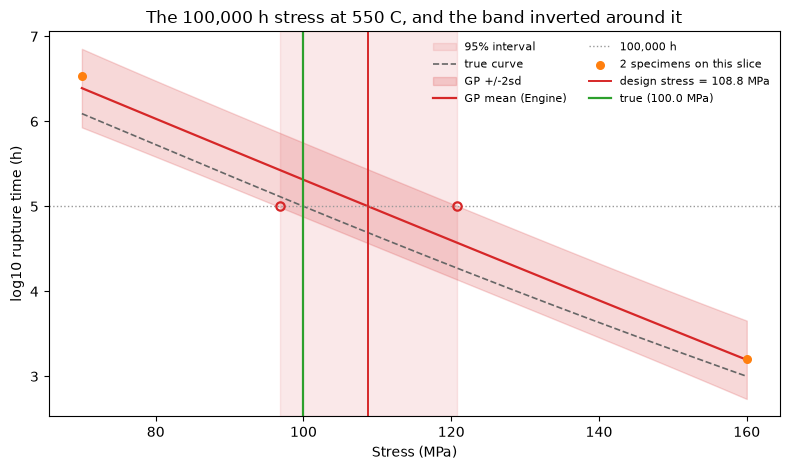

In [25]:
s_curve = posterior_curve[STRESS_COL].to_numpy()
mean_curve = posterior_curve["mean"].to_numpy()
sd_curve = posterior_curve["sd"].to_numpy()

fig, ax = plt.subplots(figsize=(8, 4.8))

# An unbounded end is drawn out to the edge of the tested range, where the
# band stopped closing - not as a bound the programme actually established.
span_low = STRESS_BOUNDS[0] if low is None else low
span_high = STRESS_BOUNDS[1] if high is None else high
ax.axvspan(span_low, span_high, color=COLOURS["design"], alpha=0.10,
           label=f"{read.credible_mass:.0%} interval")
ax.plot(stress_grid, truth_slice, color=COLOURS["truth"], lw=1.2, ls="--",
        label="true curve")
ax.fill_between(s_curve, mean_curve - 2 * sd_curve, mean_curve + 2 * sd_curve,
                color=COLOURS["posterior"], alpha=0.18, label="GP +/-2sd")
ax.plot(s_curve, mean_curve, color=COLOURS["posterior"], lw=1.6,
        label="GP mean (Engine)")
ax.axhline(target_level, color="0.6", lw=1.0, ls=":",
           label=f"{TARGET_LIFE_HOURS:,.0f} h")

# The construction, drawn: the level meets the band here and leaves it there.
for edge in (low, high):
    if edge is not None:
        ax.plot([edge], [target_level], marker="o", ms=6, mfc="none",
                mec=COLOURS["design"], mew=1.6, zorder=4)

if on_slice.any():
    ax.scatter(campaign.loc[on_slice, STRESS_COL],
               campaign.loc[on_slice, LOG_LIFE_COL],
               s=30, color=COLOURS["tests"], zorder=3,
               label=f"{int(on_slice.sum())} specimens on this slice")
ax.axvline(read.at, color=COLOURS["design"], lw=1.4,
           label=f"design stress = {read.at:.1f} MPa")
ax.axvline(true_design_stress, color=COLOURS["true_design"], lw=1.6,
           label=f"true ({true_design_stress:.1f} MPa)")

ax.set_xlabel(STRESS_COL)
ax.set_ylabel(LOG_LIFE_COL)
ax.set_title(f"The {TARGET_LIFE_HOURS:,.0f} h stress at {DESIGN_TEMPERATURE:g} C, "
             "and the band inverted around it")
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

### The estimate against the specimen count

Each iteration's slice gives a design stress and an interval, so the whole
history can be replayed. Expect the estimate to move and the interval to
breathe rather than shrink monotonically: the band is predictive, so it floors
at the material's own scatter, and an early specimen placed somewhere
informative can tighten things more than three placed later. The notes at the
end of the DBTT notebook make the same point at more length.

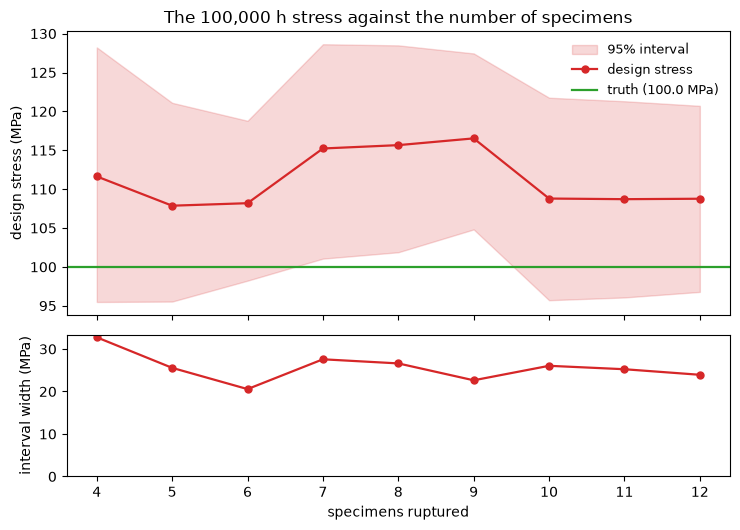

,n_tests,stress,low,high,width
0,4,111.63,95.49,128.23,32.74
1,5,107.87,95.54,121.10,25.56
2,6,108.19,98.23,118.79,20.56
3,7,115.23,101.06,128.64,27.57
4,8,115.66,101.88,128.49,26.61
5,9,116.53,104.82,127.45,22.63
6,10,108.79,95.71,121.76,26.04
7,11,108.71,96.07,121.30,25.24
8,12,108.77,96.78,120.71,23.93


In [26]:
track = []
for step in history:
    panel = step["curve"]
    try:
        step_read = crossing_from_curve(panel[STRESS_COL], panel["mean"],
                                        target_level, sd=panel["sd"])
    except ValueError:
        continue  # an early GP need not reach the target life anywhere on the slice
    track.append({
        "n_tests": step["n_tests"], "stress": step_read.at,
        # None means the band never closed within STRESS_BOUNDS; NaN leaves a
        # visible gap in the figure rather than inventing a bound.
        "low": np.nan if step_read.low is None else step_read.low,
        "high": np.nan if step_read.high is None else step_read.high,
    })

# `history` records each iteration *before* its pick is tested, so the final
# programme is only represented by the read made at the top of section 3.
track.append({"n_tests": len(campaign), "stress": read.at,
              "low": np.nan if low is None else low,
              "high": np.nan if high is None else high})
track = pd.DataFrame(track)
track["width"] = track["high"] - track["low"]

fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(7.5, 5.4), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)

top.fill_between(track["n_tests"], track["low"], track["high"],
                 color=COLOURS["design"], alpha=0.18,
                 label=f"{read.credible_mass:.0%} interval")
top.plot(track["n_tests"], track["stress"], "o-", color=COLOURS["design"],
         lw=1.6, ms=5, label="design stress")
top.axhline(true_design_stress, color=COLOURS["true_design"], lw=1.6,
            label=f"truth ({true_design_stress:.1f} MPa)")
top.set_ylabel("design stress (MPa)")
top.legend(frameon=False, fontsize=9)
top.set_title(f"The {TARGET_LIFE_HOURS:,.0f} h stress against the number of specimens")

bottom.plot(track["n_tests"], track["width"], "o-", color=COLOURS["design"], lw=1.6, ms=5)
bottom.set_xlabel("specimens ruptured")
bottom.set_ylabel("interval width (MPa)")
bottom.set_ylim(bottom=0)

fig.tight_layout()
plt.show()

track.round(2)

---
<a id="section-4"></a>
## 4. Was the active learning worth it?

Everything so far assumed that choosing *where* to test beats deciding in
advance. This section tests that, by running three fixed designs through
exactly the same machinery — upload, train on the Engine, predict the design
slice, invert the band — and putting their answers beside the active-learning
one.

| Design | Specimens | The idea |
| --- | --- | --- |
| Factorial, 5×2 | 10 | The obvious thing to do with a small budget: a grid |
| Factorial, 6×5 | 30 | The same idea with three times the specimens |
| 10 conditions, 3 repeats | 30 | The same budget as above, spent on replication instead of resolution |

The third is the interesting one. Creep scatter is large and heat-dependent,
so a test house often prefers repeats: they measure the scatter directly and
are easier to schedule around a furnace. The question is whether thirty
specimens at ten conditions tell you more about the *design stress* than thirty
specimens at thirty conditions.

> **What this comparison is and is not.** Every design is one realisation,
> drawn from the same simulator with the same noise settings. Differences of a
> megapascal or two are noise, not evidence, and a fair benchmark would repeat
> each design over many seeds and compare the *distribution* of intervals. What
> a single run can show is the shape of the thing: whether a design brackets the
> truth at all, and roughly what it costs to do so.
>
> Nor is specimen count the only currency. A creep programme is also budgeted
> in **furnace hours**, and the designs below do not spend those equally — the
> table reports the longest single test each one commits to, which is the
> number that decides whether a programme finishes this decade.

In [27]:
def factorial(n_stress: int, n_temperature: int, repeats: int = 1):
    """A grid of conditions across the box, optionally repeated."""
    stresses = np.linspace(*STRESS_BOUNDS, n_stress)
    temperatures = np.linspace(*TEMPERATURE_BOUNDS, n_temperature)
    grid = [(float(s), float(t)) for t in temperatures for s in stresses]
    return grid * repeats


BASELINES = [
    ("Factorial, 5x2", factorial(5, 2)),
    ("Factorial, 6x5", factorial(6, 5)),
    ("10 conditions, 3 repeats", factorial(5, 2, repeats=3)),
]


def run_fixed_design(label: str, conditions) -> dict:
    """Take one fixed design all the way to a design stress, through the Engine.

    The same path section 2 took, minus the loop: upload the programme, train a
    GP on it, predict the design slice, and invert the band. Each design gets
    its own resources so nothing here disturbs the active-learning ones, and
    re-running the notebook versions them in place rather than piling up.
    """
    slug = label.lower().replace(",", "").replace(" ", "_").replace("x", "by")
    design = simulator.run(list(conditions), start_index=1)

    dataset = upload_dataset(client, project_id, design, f"creep_baseline_{slug}")
    training = build_training_workflow(
        client, project_id, dataset, f"creep_gp_{slug}",
        kernel=KERNEL, model_type=MODEL_TYPE, warp_inputs=WARP_INPUTS, seed=MODEL_SEED,
    )
    run_saved(client, project_id,
              save_workflow(client, project_id, training, f"Creep baseline train - {label}"))
    model = resource_id(client, project_id, f"creep_gp_{slug}", "model")

    prediction = build_prediction_workflow(
        client, project_id, model, STRESS_BOUNDS,
        f"creep_mean_{slug}", f"creep_sd_{slug}", fixed=DESIGN_SLICE,
    )
    response = run_saved(client, project_id,
                         save_workflow(client, project_id, prediction,
                                       f"Creep baseline predict - {label}"))
    curve = saved_prediction(client, project_id, response)

    return {"label": label, "design": design, "curve": curve,
            "read": crossing_from_curve(curve[STRESS_COL], curve["mean"],
                                        target_level, sd=curve["sd"])}


results = []
for label, conditions in BASELINES:
    print(f"{label} ({len(conditions)} specimens) ...", end=" ", flush=True)
    results.append(run_fixed_design(label, conditions))
    print(results[-1]["read"])

Factorial, 5x2 (10 specimens) ... 

CurveCrossing(at=105.06, 95% interval [95.44, 114.44])
Factorial, 6x5 (30 specimens) ... 

CurveCrossing(at=98.30, 95% interval [85.98, 110.38])
10 conditions, 3 repeats (30 specimens) ... 

CurveCrossing(at=98.58, 95% interval [82.70, 114.48])


### Side by side

In [28]:
def summarise(label: str, design: pd.DataFrame, at) -> dict:
    inside = (at.low is not None and at.high is not None
              and at.low <= true_design_stress <= at.high)
    return {"design": label, "specimens": len(design),
            "longest test (h)": design[LIFE_COL].max(),
            "design stress (MPa)": at.at,
            "low": np.nan if at.low is None else at.low,
            "high": np.nan if at.high is None else at.high,
            "width (MPa)": np.nan if at.width is None else at.width,
            "error (MPa)": at.at - true_design_stress,
            "contains truth": inside}


comparison = pd.DataFrame(
    [summarise(f"Active learning ({ACQUISITION})", campaign, read)]
    + [summarise(r["label"], r["design"], r["read"]) for r in results]
)
comparison.round(2)

,design,specimens,longest test (h),design stress (MPa),low,high,width (MPa),error (MPa),contains truth
0,Active learning (qNIPV),12,3462935.1,108.77,96.78,120.71,23.93,8.77,True
1,"Factorial, 5x2",10,1709145.5,105.06,95.44,114.44,19.00,5.06,True
2,"Factorial, 6x5",30,859057.5,98.30,85.98,110.38,24.40,-1.70,True
3,"10 conditions, 3 repeats",30,2036922.3,98.58,82.70,114.48,31.78,-1.42,True


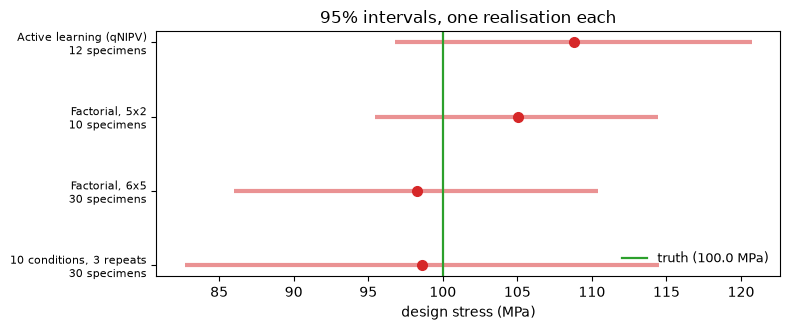

In [29]:
fig, ax = plt.subplots(figsize=(8, 3.4))

rows = comparison.iloc[::-1].reset_index(drop=True)   # first design at the top
for y, row in rows.iterrows():
    colour = COLOURS["design"] if row["contains truth"] else "firebrick"
    ax.plot([row["low"], row["high"]], [y, y], lw=3, color=colour, alpha=0.5,
            solid_capstyle="butt")
    ax.plot([row["design stress (MPa)"]], [y], "o", ms=7, color=colour)

ax.axvline(true_design_stress, color=COLOURS["true_design"], lw=1.6,
           label=f"truth ({true_design_stress:.1f} MPa)")
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{r['design']}\n{r['specimens']} specimens"
                    for _, r in rows.iterrows()], fontsize=8)
ax.set_xlabel("design stress (MPa)")
ax.set_title(f"{read.credible_mass:.0%} intervals, one realisation each")
ax.legend(frameon=False, fontsize=9, loc="lower right")
fig.tight_layout()
plt.show()

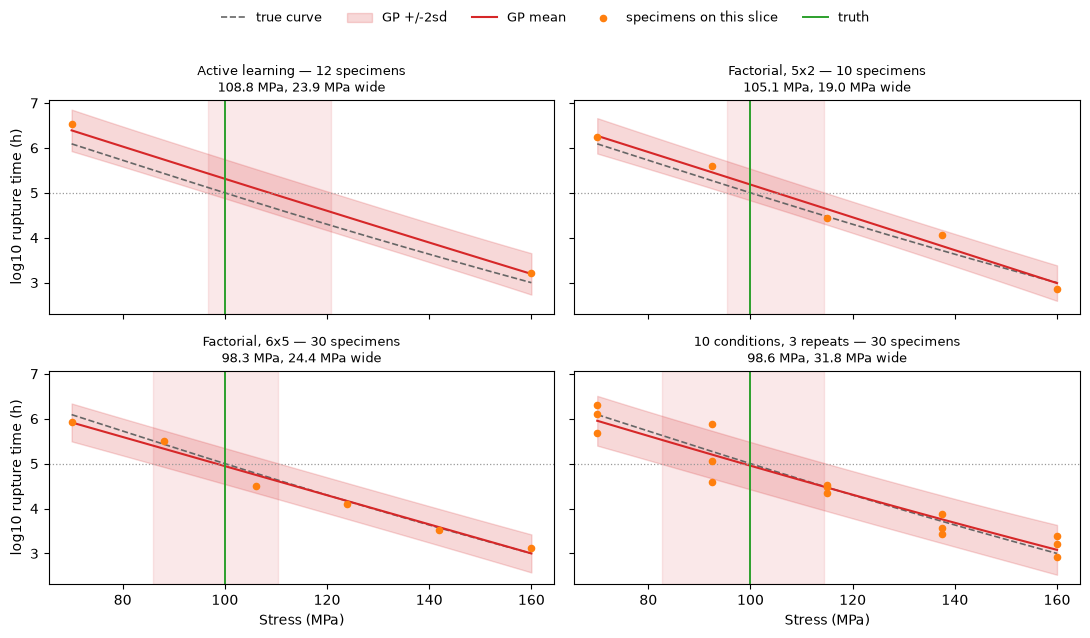

In [30]:
panels = [("Active learning", campaign, posterior_curve, read)] + [
    (r["label"], r["design"], r["curve"], r["read"]) for r in results
]

fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), sharex=True, sharey=True)
for ax, (label, design, curve, at) in zip(axes.ravel(), panels):
    stress = curve[STRESS_COL].to_numpy()
    mean, sd = curve["mean"].to_numpy(), curve["sd"].to_numpy()

    if at.low is not None and at.high is not None:
        ax.axvspan(at.low, at.high, color=COLOURS["design"], alpha=0.10)
    ax.plot(stress_grid, truth_slice, color=COLOURS["truth"], lw=1.2, ls="--",
            label="true curve")
    ax.fill_between(stress, mean - 2 * sd, mean + 2 * sd,
                    color=COLOURS["posterior"], alpha=0.18, label="GP +/-2sd")
    ax.plot(stress, mean, color=COLOURS["posterior"], lw=1.5, label="GP mean")
    ax.axhline(at.level, color="0.6", lw=0.9, ls=":")

    here = np.isclose(design[TEMPERATURE_COL], DESIGN_TEMPERATURE)
    if here.any():
        ax.scatter(design.loc[here, STRESS_COL], design.loc[here, LOG_LIFE_COL],
                   s=20, color=COLOURS["tests"], zorder=3,
                   label="specimens on this slice")
    ax.axvline(true_design_stress, color=COLOURS["true_design"], lw=1.4,
               label="truth")

    width = "unbounded" if at.width is None else f"{at.width:.1f} MPa wide"
    ax.set_title(f"{label} — {len(design)} specimens\n{at.at:.1f} MPa, {width}",
                 fontsize=9)

for ax in axes[-1]:
    ax.set_xlabel(STRESS_COL)
for ax in axes[:, 0]:
    ax.set_ylabel(LOG_LIFE_COL)

handles, labels = axes[0, 0].get_legend_handles_labels()
seen_labels = dict(zip(labels, handles))
fig.legend(seen_labels.values(), seen_labels.keys(),
           loc="upper center", ncol=5, frameon=False, fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### What that says

**Active learning came last.** All four designs bracket the truth, so none is
*wrong*, but the ordering is not the one the DBTT notebook produced:

| Design | Specimens | Width | Error |
| --- | --- | --- | --- |
| Factorial, 5×2 | 10 | **19.00 MPa** | +5.06 |
| Active learning (qNIPV) | 12 | 23.93 MPa | **+8.77** |
| Factorial, 6×5 | 30 | 24.40 MPa | −1.70 |
| 10 conditions, 3 repeats | 30 | 31.78 MPa | −1.42 |

Ten specimens on a coarse grid gave a narrower interval than twelve chosen by
the acquisition, and the active-learning point estimate was the furthest from
the truth of the four. That is a real result, not a bad seed, and the reason is
visible in the figure above.

**The acquisition optimised a different question from the one we asked.** Of
the eight conditions it chose, the test temperatures ran from 565.7 °C to
632.2 °C with a mean of 595.7 °C, and **not one** fell within 10 °C of the
550 °C design temperature. That is `qNIPV` behaving exactly as specified: it
minimises *integrated* posterior variance over the whole box, and the corners
were already pinned by the seed design, so the interior is where the integral
had most to gain. The design stress, meanwhile, is read along a single line at
the edge of that box. The factorial designs sweep temperature at 550 °C and
650 °C, which puts five of their ten specimens directly on the line the
question is asked on — and they never had to be clever to do it.

**Why the DBTT notebook came out the other way.** There the quantity of
interest sat in the middle of a one-dimensional range, so reducing variance
everywhere necessarily reduced it where it mattered; the acquisition could not
help but help. The second dimension breaks that coupling. It buys the real
Larson–Miller trade — the model does learn the temperature–time equivalence,
which is why a 550 °C answer is obtainable from 600 °C data at all — but it
also gives the acquisition somewhere to spend a budget that the question never
looks at.

**What would fix it**, in order of how much work each is:

1. Put `DESIGN_TEMPERATURE` inside the box rather than on its edge, so that
   "reduce variance everywhere" overlaps with "reduce variance here".
2. Restrict the search to the design slice, by training on a sub-box or
   recommending against a slice model. `Recommend` takes no bounds, so this has
   to be arranged through the data rather than asked for.
3. Use a goal-oriented acquisition — one that reduces the variance *of the
   quantity being estimated* rather than of the surface. None of the seven in
   `ACQUISITIONS` is that; they reduce variance or chase optima, and a design
   stress is neither.

**Two honest qualifications.** Each design is a single realisation, so a
megapascal or two is noise and the ordering of the two 30-specimen designs is
not meaningful. And specimen count is not the only currency: active learning
committed to a single test of 3.46 million hours, where the 6×5 factorial's
longest was 859,000 — a difference no table of interval widths will charge it
for, and one that would decide whether either programme could be run at all.

---
## Notes

- **The interval is the deliverable, not the point estimate.** A programme of
  this size pins the design stress down to a few megapascals; quoting a single
  number hides that, and a creep allowable is exactly the kind of number that
  gets quoted without one.
- **Two dimensions are what make the trade possible.** The Larson–Miller
  parameter says a hotter, shorter test carries the same information as a
  cooler, longer one. A one-dimensional campaign at a fixed temperature cannot
  make that trade; this one can, and the acquisition makes it without being
  told the parameter exists. What it is actually minimising is integrated
  posterior variance over the whole box — the design-life contour is our
  question, not its.
- **The band is pointwise, so the coverage is approximate.** The interval is
  the set of stresses at which a pointwise credible band still contains the
  target life. Inverting a pointwise band does not give exactly the nominal
  mass — a simultaneous band would, and would be wider. What it does avoid is
  the delta method's linearisation: nothing here is divided by the slope of
  the curve, so a flat, poorly resolved stress dependence widens the interval
  instead of being flattered by it, and the result is asymmetric in general.
- **The band is predictive, so the interval is conservative.** It carries the
  material's specimen-to-specimen scatter, which means it answers "at what
  stress could a fresh specimen last exactly the design life?" rather than
  "where does the underlying master curve cross it?". The second is the
  narrower question and the one a design code wants; separating them needs the
  epistemic part of the variance on its own, which the Engine does not return.
  Read the interval as the conservative of the two.
- **An end can be unbounded.** If the band still straddles the target life at
  the edge of the slice, that end comes back as `None`: the programme does not
  bound the design stress on that side. Widen `STRESS_BOUNDS` rather than
  reporting a number the data does not support.
- **The design temperature is not free.** The design stress falls steeply with
  temperature — by 600 °C the 100,000 hour stress is 58 MPa, below
  `STRESS_BOUNDS` — so the box has to be chosen around the question. Ask a
  different design temperature and you must move the box with it, or the
  crossing will simply not exist on the slice and `crossing_from_curve` will
  say so.
- **The simulator grants tests nobody would run.** This is the single largest
  difference between the notebook and practice. Real creep assessment never
  observes the design life: it tests for a few thousand hours and extrapolates,
  and the uncertainty that matters is the extrapolation's, not the
  interpolation's. Capping the simulator at a realistic test duration would
  turn long tests into **censored** observations — as the fatigue notebook's
  runouts are — and a GP fitted to censored values read as if they were
  measurements is biased exactly where it is read. Doing that properly needs a
  censored likelihood, which is a different model, not a different kernel.
- **The master curve has a turning point.** The quadratic in $\log_{10}\sigma$
  turns over at 29.1 MPa, below which it claims that less stress means a
  shorter life. `LarsonMillerParams.turning_stress` exposes it and the config
  refuses a stress range that reaches it. That is a property of the fitted form,
  not of the material, and it is the usual reason published master curves carry
  a stated range of validity.